# Chapter 4: Mapping Many-Body Hamiltonians to Qubits

*This chapter describes how to translate many-body quantum problems into a form suitable for quantum hardware. We explain fermion-to-qubit encoding techniques such as the Jordan–Wigner and Bravyi–Kitaev transformations, which map fermionic creation and annihilation operators to Pauli operators on qubits. The mapping of spin Hamiltonians and the choice of computational basis states (for example in an occupation-number basis) are also discussed. We examine how symmetries and conserved quantities (particle number, spin, etc.) can reduce resource requirements. We illustrate these mappings with explicit model Hamiltonians and showing how many-body Hamiltonians can be implemented on quantum circuits.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

Chapter 2 described a quantum computer as a
register of qubits acted on by unitary gates and read out by
measurements in the computational basis; Chapter 3
described a many-body system as a Fock space acted on by creation and
annihilation operators. To run a many-body calculation on a quantum
computer the two descriptions have to be connected, and this chapter is
about that connection. Three things must be translated. The
*states*: an occupation-number state
$\vert n_0n_1\cdots n_{M-1}\rangle$ of $M$ fermionic modes looks exactly
like a computational basis state of $M$ qubits, and the obvious
identification, one qubit per mode with $\vert 1\rangle$ meaning
occupied, is the one we shall use. The *operators*: the creation
and annihilation operators anticommute, whereas operators on different
qubits commute, and the resolution of this conflict is the
Jordan--Wigner transformation, which we have in fact already met as the
string of $Z$ matrices in Eq. (3.9). And the
*Hamiltonian*: once every $a^{\dagger}_pa_q$ and
$a^{\dagger}_pa^{\dagger}_qa_sa_r$ is a product of Pauli matrices, the
Hamiltonian is a sum of such products, a *Pauli sum*, and it is in
this form that every quantum algorithm of the following chapters
consumes it. Time evolution (Chapter 5) exponentiates
the Pauli sum term by term; phase estimation (Chapter 6)
applies the resulting circuit under control of an ancilla; the
variational algorithms (Chapter 7) measure the Pauli sum
term by term.

The translation is exact and, for the operators, unique up to
conventions. What is not unique is its cost. The number of qubits, the
number of Pauli strings in the Hamiltonian and the number of qubits each
string touches, its *weight*, are the three quantities that decide
whether a calculation fits on a given device, and all three depend on
choices: which single-particle basis, which ordering of the modes, and
above all which symmetry of the problem has been used to shrink the
register before the mapping is applied. The models of
Chapter 3 were chosen because each has such a
symmetry, and the second half of this chapter shows what each symmetry
is worth on a qubit register. The last sections turn the Pauli sums into
circuits: the exponential of a single Pauli string, the Trotter step of
a Hamiltonian, the preparation of a reference determinant, the
measurement of an energy from a finite number of shots, and finally the
unitary coupled-cluster circuit for the pairing model, which reproduces
the numbers of Section *Unitary coupled cluster* with four rotation angles on
four qubits and is the first variational quantum calculation of the
book.


## Pauli strings and Pauli sums

A *Pauli string* on $n$ qubits is a tensor product of one Pauli
matrix or identity per qubit,

$$
P = \sigma_0\otimes\sigma_1\otimes\cdots\otimes\sigma_{n-1},
\qquad \sigma_q\in\{I,X,Y,Z\},\tag{4.1}
$$

which we write as a word such as $ZZXI$, or as $Z_0Z_1X_2$ when the
identities are left out, with qubit $0$ the leftmost factor as in
Chapters 2 and 3. The
*weight* of a string is the number of factors different from $I$.
There are $4^n$ strings, they are Hermitian and unitary, they square to
the identity, and the product of two strings is again a string up to a
phase $\pm1$ or $\pm i$, obtained factor by factor from the
single-qubit rule $\sigma_i\sigma_j=\delta_{ij}I+i\epsilon_{ijk}\sigma_k$.
Two strings either commute or anticommute: they anticommute if and only
if they differ, both being non-identity, on an odd number of qubits.
Finally the strings are orthogonal with respect to the trace inner
product, $\mathrm{Tr}(PQ)=2^n\delta_{PQ}$, and since there are $4^n$ of
them they form a basis of the $2^n\times2^n$ matrices. Every Hermitian
operator on the register is therefore a *Pauli sum*

$$
\hat{H} = \sum_\alpha h_\alpha P_\alpha,
\qquad
h_\alpha = \frac{1}{2^n}\mathrm{Tr}\left(P_\alpha\hat{H}\right)\in\mathbb{R} ,\tag{4.2}
$$

with real coefficients. Equation (4.2) is a
constructive statement: given any matrix, $4^n$ traces produce its
Pauli decomposition, and the class `PauliSum` in
`pauli.py` does this, more cleverly than by $4^n$ full traces,
by contracting one qubit at a time. It stores a Pauli sum as a
dictionary from strings to coefficients and implements the algebra,


In [2]:
from pauli import PauliSum

X0 = PauliSum.single(2, 0, "X"); Y0 = PauliSum.single(2, 0, "Y"); Z1 = PauliSum.single(2, 1, "Z")
print(X0 * Y0)                          # +(0.0000+1.0000j) ZI
print(X0.commutator(Z1))                # 0
H = PauliSum({"ZZ": 0.5, "XX": 0.25, "YY": 0.25, "IZ": -0.3})
print(H.matrix().shape, H.n_strings(), H.max_weight(), H.weights())
print(PauliSum.from_matrix(H.matrix()).terms == H.terms)


+(0.0000+1.0000j) ZI
0
(4, 4) 4 2 {1: 1, 2: 3}
False


For a random Hermitian $8\times8$ matrix the decomposition has all $64$
strings, one of weight zero, nine of weight one, and twenty-seven each
of weights two and three, which is the generic situation and the one
to be avoided. A structured Hamiltonian has far fewer strings, and the
point of this chapter is to show how many, and how to keep the number
small.

Why this form? Because the Pauli strings are exactly the operators a
quantum computer can handle natively. The exponential of a single
string, $e^{-i\theta P}$, is a short circuit (Section *From Pauli strings to circuits*);
the expectation value of a single string is obtained from measurements
in the computational basis after a layer of single-qubit rotations
(Section *Measuring a Pauli sum*); and both procedures cost a number of
gates proportional to the weight of the string. A Pauli sum with $K$
strings of weight at most $w$ can thus be time-evolved with
$\mathcal{O}(Kw)$ gates per Trotter step and its energy can be measured
with at most $K$ distinct measurement settings. These are the cost
functions against which the mappings below are judged.

### Pauli sums on a classical computer

A Pauli sum is also a convenient representation for classical
computation, and the programs of this and the following chapters use it
as such. The product $\hat{H}\vert\Psi\rangle$ never requires the
$2^n\times2^n$ matrix: each string acts on the tensor of amplitudes
$\Psi_{i_0i_1\cdots i_{n-1}}$ one factor at a time, a $2\times2$ matrix
applied along one index, so that the cost of the product is
$\mathcal{O}(K\,w\,2^n)$ for $K$ strings of weight $w$ rather than
$\mathcal{O}(4^n)$, and the memory is that of the state alone. The
method `apply` of `PauliSum` does this, and combined with
the Lanczos iteration of Section *Iterative eigensolvers* it diagonalizes the
eight-qubit Hubbard Hamiltonian of Section *The Hubbard model: the order of the modes*, $29$
strings on $256$ amplitudes, in thirty steps and a few hundredths of a
second, reproducing the $-2.10274848$ of Table 3.3. This
is exactly what a classical exact-diagonalization code does with bit
strings instead of Pauli strings, and it is what every simulator of
quantum circuits does with gates; the number of qubits it can reach is
limited by the $2^n$ amplitudes, about thirty on a laptop and fifty on
a supercomputer, which is the exponential wall of
Section *The exponential wall* seen from the qubit side.

Two numbers that will be needed in Chapter 5 are
also read off from the Pauli sum. The triangle inequality gives
$\Vert\hat{H}\Vert\le\sum_\alpha\vert h_\alpha\vert$, an upper bound on
the largest eigenvalue in absolute value which fixes the time scale of
the dynamics, and the first-order Trotter error of
Eq. (3.45) is bounded by the sum of the commutators
of the pieces, $\sum_{\alpha<\beta}\vert h_\alpha h_\beta\vert\,\Vert[P_\alpha,P_\beta]\Vert$,
which for Pauli strings is simply twice the sum of
$\vert h_\alpha h_\beta\vert$ over the pairs of strings that anticommute,
since $[P_\alpha,P_\beta]$ is either zero or $2P_\alpha P_\beta$ with
$\Vert P_\alpha P_\beta\Vert=1$. Table 4.1 lists both for
the Hamiltonians of Section *Symmetries and encodings*. The norm bound
overestimates the norm by a factor of one and a half or so, and the
commutator bound, which decides how many Trotter steps a given accuracy
requires, is an order of magnitude larger for the Hubbard ring than
for the four-qubit models: the Hubbard hopping strings anticommute with
many of their neighbours, the Heisenberg strings with few.

| Hamiltonian | $\sum_\alpha\vert h_\alpha\vert$ | $\Vert\hat{H}\Vert$ | commutator bound |
|---|---|---|---|
| Lipkin, one qubit per doublet | $6.000$ | $4.213$ | $8.583$ |
| pairing $L=4$, one qubit per level | $13.500$ | $10.672$ | $19.500$ |
| pairing $L=4$, one qubit per orbital | $14.500$ | $10.672$ | $19.500$ |
| Hubbard ring, spin-major ordering | $24.000$ | $16.000$ | $72.000$ |
| Heisenberg ring | $3.000$ | $2.000$ | $3.000$ |

*Table 4.1: Two bounds read off from a Pauli sum: $\sum_\alpha\vert h_\alpha\vert$
against the exact spectral norm, and the commutator sum
$\sum_{\alpha<\beta}\vert h_\alpha h_\beta\vert\,\Vert[P_\alpha,P_\beta]\Vert$
that controls the first-order Trotter error, for the Hamiltonians of
Section *Symmetries and encodings* at $\xi=g=J=t=1$, $U=4$. Produced by
`mapped_models.py`.*


## The Jordan--Wigner transformation

### Why the naive map fails

A single fermionic mode is a two-level system, and
Eq. (3.8) identified its operators with those of a qubit:
$a^{\dagger}=\vert 1\rangle\langle 0\vert=\sigma^+$ and
$a=\vert 0\rangle\langle 1\vert=\sigma^-$ with

$$
\sigma^{\pm} = \frac{X\mp iY}{2},
\qquad
\hat{n} = \sigma^+\sigma^- = \frac{I-Z}{2} .\tag{4.3}
$$

Note the sign: with $\vert 1\rangle$ occupied and the matrix convention
of Chapter 2, $Z\vert 1\rangle=-\vert 1\rangle$, the
raising operator that creates an occupation is $(X-iY)/2$. For $M$
modes one is tempted to write $a_p=I\otimes\cdots\otimes\sigma^-\otimes\cdots\otimes I$,
that is $\sigma^-_p$ on qubit $p$. This reproduces
$\{a_p,a^{\dagger}_p\}=I$ and $a_p^2=0$ on every single qubit, but
operators on different qubits commute, so $\{a_0,a_1\}=2\sigma^-_0\sigma^-_1$
instead of zero; `jw_basics.py` prints its Pauli form,
$\frac12(XX+iXY+iYX-YY)$, and its spectral norm, $2$. A Hamiltonian built
from such operators would describe hard-core bosons
(Section *Bosons and spins*), not fermions, and would get every sign of
every exchange wrong.

### The transformation

The correct answer was derived in Section *Operators as matrices*. The
sign rule of Eq. (3.7) requires $a_p$ to multiply the
state by $(-1)^{\sum_{q<p}n_q}$, and this is the eigenvalue of
$\prod_{q<p}Z_q$; inserting it turns Eq. (3.9) into

$$
a_p = Z_0Z_1\cdots Z_{p-1}\,\sigma^-_p
 = Z_0Z_1\cdots Z_{p-1}\,\frac{X_p+iY_p}{2},
\qquad
a^{\dagger}_p = Z_0Z_1\cdots Z_{p-1}\,\frac{X_p-iY_p}{2},\tag{4.4}
$$

the *Jordan--Wigner transformation*. The product of $Z$'s is the
*parity string*: it measures the parity of the
number of occupied modes to the left of $p$, and it is what a fermionic
operator has to know about the rest of the register. That
Eq. (4.4) satisfies the anticommutation relations of
Eq. (3.3) can be checked symbolically: for
$p<q$, $a_pa_q$ and $a_qa_p$ differ by the order of $\sigma^-_p$ and the
$Z_p$ in the parity string of $a_q$, and $Z\sigma^-=-\sigma^-Z$ supplies
the sign, while all other factors commute. The program
`jordanwigner.py` performs this check for all pairs of modes, and
also verifies that the Pauli sums of Eq. (4.4) equal, as
matrices, the operators of `FockSpace` from
Chapter 3, which is the statement that the two
chapters use one and the same convention. The class is short,


In [3]:
class JordanWigner:
    def __init__(self, n_modes):
        self.n = n_modes

    def _zstring(self, p):                    # Z_0 ... Z_{p-1}
        return PauliSum({"".join(["Z"] * p + ["I"] * (self.n - p)): 1.0}, self.n)

    def sigma_plus(self, p):                  # (X_p - i Y_p)/2 = |1><0| on qubit p
        return PauliSum.single(self.n, p, "X", 0.5) + PauliSum.single(self.n, p, "Y", -0.5j)

    def create(self, p):
        return self._zstring(p) * self.sigma_plus(p)

    def annihilate(self, p):
        return self.create(p).dagger()

    def number(self, p):                      # (I - Z_p)/2
        return 0.5 * PauliSum.identity(self.n) - PauliSum.single(self.n, p, "Z", 0.5)

    def map_hamiltonian(self, h, v):          # sum h_pq a+_p a_q + 1/4 sum v_pqrs a+_p a+_q a_s a_r
        ...


and `map_hamiltonian` does nothing more than multiply out the
products of Eq. (3.10) as Pauli sums, letting the
dictionary collect the strings. Two remarks on conventions. First, the
ordering of the modes is a choice, and a different ordering gives a
different, unitarily equivalent set of strings; Section *The Hubbard model: the order of the modes*
shows that the choice matters. Second, the literature is divided on
whether $\vert 0\rangle$ or $\vert 1\rangle$ means occupied and hence on
the sign of $Y$ in Eq. (4.4); the physics is the same,
but Pauli forms copied from different sources cannot be combined without
checking. We use $\vert 1\rangle$ for occupied throughout.

### Operator identities

Every term of a many-body Hamiltonian is a product of two or four of
the operators of Eq. (4.4), and a handful of identities
cover all of them. The *number operator* has no parity string,
since $Z^2=I$,

$$
\hat{n}_p = a^{\dagger}_pa_p = \frac{I-Z_p}{2},
\qquad
\sum_p\varepsilon_p\hat{n}_p = \frac12\sum_p\varepsilon_p\left(I-Z_p\right) ,\tag{4.5}
$$

so a non-interacting Hamiltonian is diagonal on the register and needs
no circuit to find its spectrum, only to prepare its eigenstates. The
*hopping* term between modes $p<q$ carries the parity string of the
modes in between,

$$
a^{\dagger}_pa_q + a^{\dagger}_qa_p
 = \frac12\left(X_pZ_{p+1}\cdots Z_{q-1}X_q + Y_pZ_{p+1}\cdots Z_{q-1}Y_q\right) ,\tag{4.6}
$$

two strings of weight $q-p+1$: a hop has to know how many particles it
jumps over. The *pair-creation* term differs from it by one sign,

$$
a^{\dagger}_pa^{\dagger}_q + a_qa_p
 = \frac12\left(X_pZ_{p+1}\cdots Z_{q-1}X_q - Y_pZ_{p+1}\cdots Z_{q-1}Y_q\right) ,\tag{4.7}
$$

and that one sign is the whole difference, on a quantum computer,
between the hopping term of the Hubbard model and the pair-transfer term
of the pairing model. Finally a *two-body* term with four distinct
indices produces eight strings of weight four with coefficients
$\pm\frac18$; for four consecutive modes, where the intermediate parity
strings are empty,

$$
\begin{eqnarray}
a^{\dagger}_0a^{\dagger}_1a_3a_2 + \mathrm{h.c.}
 &=& \frac18\big(XXXX + XYXY + XYYX + YXXY + YXYX + YYYY
\nonumber\\
 && \qquad - XXYY - YYXX\big) ,
\end{eqnarray}
$$

where $XYXY$ means $X_0Y_1X_2Y_3$. All four identities are printed and
asserted by `jw_basics.py`, which also confirms that the
eight-string form is what the pair-transfer term $\hat{P}^+_p\hat{P}^-_q+\mathrm{h.c.}$
of the pairing model becomes when the modes are ordered
$(p+,p-,q+,q-)$. For a general two-body Hamiltonian the number of
strings grows as $\mathcal{O}(M^4)$ and the longest of them span the
whole register.

### The cost for a generic Hamiltonian

Table 4.2 gives the count for a Hamiltonian of the
form of Eq. (3.10) with random one- and two-body matrix
elements on $M$ modes: $6$, $19$, $55$, $136$ and $292$ strings for
$M=2,\ldots,6$, a small fraction of the $4^M$ strings available and
consistent with $\mathcal{O}(M^4)$, but with a largest weight equal to
$M$, because the parity strings of the hopping terms between the first
and the last mode reach across everything. For a molecule with $M=100$
spin-orbitals this means of order $10^7$ strings, some of weight $100$,
which is why the mapping of quantum chemistry to qubits is a research
field of its own. The program `jw_basics.py` checks, for
$M\le4$, that the Pauli sum equals the Fock-space matrix of
Chapter 3, so that the counts are counts of an exact
decomposition.

| $M$ | $4^M$ | Pauli strings | largest weight |
|---|---|---|---|
| $2$ | $16$ | $6$ | $2$ |
| $3$ | $64$ | $19$ | $3$ |
| $4$ | $256$ | $55$ | $4$ |
| $5$ | $1024$ | $136$ | $5$ |
| $6$ | $4096$ | $292$ | $6$ |

*Table 4.2: Pauli strings in the Jordan--Wigner image of a generic one-
plus two-body Hamiltonian on $M$ modes. The count grows as
$\mathcal{O}(M^4)$ but the largest weight is $M$. Produced by
`jw_basics.py`.*

The Jordan--Wigner transformation is exact and the easiest to derive,
but it is not the only fermion-to-qubit mapping, and the alternatives
attack the weight. All of them store, on each qubit, some parity of a
subset of the occupation numbers, and differ in which subsets. The
Jordan--Wigner mapping stores $n_j$ itself, so that the occupation is
local, $\hat{n}_p=(I-Z_p)/2$, but the parity needed by $a_p$ has to be
collected from all qubits to its left. The *parity
mapping* stores on qubit $j$ the cumulative parity
$n_0\oplus\cdots\oplus n_j$; then the parity needed by $a_p$ sits on the
single qubit $p-1$, but the occupation becomes
$\hat{n}_p=(I-Z_{p-1}Z_p)/2$, and creating a particle in mode $p$
changes the cumulative parity of every qubit $j\ge p$, so the ladder
operators carry a string $X_{p+1}\cdots X_{M-1}$ of *updates*
instead of a string of parities. Nothing is gained: the strings have
simply moved from one end of the register to the other, as the second
row of each block of Table 4.3 shows. The
*Bravyi--Kitaev mapping* stores
partial parities arranged in a binary tree, qubit $j$ holding the parity
of a set of modes that is a single mode for even $j$, a pair for
$j\equiv1\pmod4$, a block of four for $j\equiv3\pmod8$, and so on, so
that both the parity that $a_p$ has to read and the set of qubits it
has to update involve $\mathcal{O}(\log M)$ qubits. For $M=8$ every
$a^{\dagger}_p$ has weight four in the Bravyi--Kitaev mapping, against
weights up to eight in the other two, and the advantage grows with $M$.
The class `BravyiKitaev` in `jordanwigner.py` implements
the encoding as a permutation of the Fock basis, $b=\beta n\bmod2$ with
the recursively defined matrix $\beta$, followed by the decomposition of
Eq. (4.2); it is exact but limited to eight
modes. The lower half of Table 4.3 carries a warning,
however. For the structured Hamiltonians of this book, whose operators
act on adjacent modes when the modes are ordered well, the
Jordan--Wigner strings are already short, and the Bravyi--Kitaev
mapping makes them *longer*, weight six instead of four for the
pairing model, because the tree structure ignores the locality of the
problem. The asymptotic advantage of the cleverer mappings is real for
generic Hamiltonians with $\mathcal{O}(M^4)$ long-range terms, such as
those of quantum chemistry; for the small, structured models here the
Jordan--Wigner transformation with a good ordering of the modes is the
right choice, and that is what the next section does model by model.

| mapping | weights of $a^{\dagger}_p$, $M=4$ | weights of $a^{\dagger}_p$, $M=8$ |
|---|---|---|
| Jordan--Wigner | $1,2,3,4$ | $1,2,3,4,5,6,7,8$ |
| parity | $4,4,3,2$ | $8,8,7,6,5,4,3,2$ |
| Bravyi--Kitaev | $3,3,3,3$ | $4,4,4,4,4,4,4,4$ |
| mapping | pairing, $L=4$ (strings, weight) | Hubbard ring (strings, weight) |
| Jordan--Wigner | $61$, $4$ | $29$, $4$ |
| parity | $61$, $6$ | $29$, $5$ |
| Bravyi--Kitaev | $61$, $6$ | $29$, $5$ |

*Table 4.3: Three fermion-to-qubit mappings. Top: the weight of
$a^{\dagger}_p$ for every mode $p$ on $M=4$ and $M=8$ qubits. Bottom:
number of strings and largest weight of the pairing Hamiltonian with
$L=4$ and of the four-site Hubbard ring in the spin-major ordering, both
on eight qubits. Produced by `jw_basics.py`.*

### A Hamiltonian on two qubits

The two-mode Hamiltonian of Eq. (3.22) is the smallest
complete example. With Eqs. (4.5)
and (4.6), and
$\hat{n}_0\hat{n}_1=(I-Z_0)(I-Z_1)/4$,

$$
\hat{H} = \left(\frac{\varepsilon_0+\varepsilon_1}{2}+\frac{U}{4}\right)I
 - \frac{2\varepsilon_0+U}{4}Z_0 - \frac{2\varepsilon_1+U}{4}Z_1
 + \frac{U}{4}Z_0Z_1 + \frac{t}{2}\left(X_0X_1+Y_0Y_1\right) ,\tag{4.9}
$$

six Pauli strings, none of weight greater than two, which is the $M=2$
entry of Table 4.2. Its matrix in the basis
$\vert 00\rangle,\vert 01\rangle,\vert 10\rangle,\vert 11\rangle$ is
Eq. (3.23), block diagonal because the strings
$Z_0$, $Z_1$, $Z_0Z_1$ are diagonal and $X_0X_1+Y_0Y_1$ flips the two
qubits in opposite directions, conserving the number of ones. For
$\varepsilon_0=1$, $\varepsilon_1=2$, $t=0.3$ and $U=0.5$ the
coefficients are $1.625$, $-0.625$, $-1.125$, $0.125$ and $0.15$, and the
one-particle block has the eigenvalues $0.9169$ and $2.0831$ of
Section *A worked example: two modes*. Everything a quantum computer will be
asked to do with a Hamiltonian in this book can be practised on
Eq. (4.9): a Trotter step is five rotations, the energy
is three measurement settings, and the exact ground state in the
one-particle sector is reached from $\vert 10\rangle$ by a single
two-qubit rotation.


## Symmetries and encodings

The generic mapping of Section *The Jordan--Wigner transformation* uses one qubit
per single-particle mode and lets the Hamiltonian act on the whole Fock
space, all particle numbers included. That is wasteful for the same
reason that full diagonalization is wasteful in Chapter 3:
a symmetry of the Hamiltonian restricts the physics to a sector, and if
the sector can be parametrized by fewer bits, fewer qubits are needed
and the operators on them are shorter. Every model of
Section *Four model Hamiltonians* is a case in point, and we take them in
turn. The recipe is always the same. Identify the conserved quantity;
choose a basis of the relevant sector whose states are labelled by bit
strings; write the Hamiltonian in that basis in terms of operators that
act on single bits; and map those operators onto Pauli matrices. When
the operators are fermionic this is the Jordan--Wigner transformation
restricted to a sector; when they are hard-core bosonic or spin
operators, as in Section *Bosons and spins*, the parity strings
disappear.

One convention has to be fixed once and for all, because the models of
Chapter 3 were written with two different ones. We
take $\vert 0\rangle$ to be the "lower" or "empty" state of every
qubit and $\vert 1\rangle$ the "upper" or "occupied" one, as in
Eq. (4.4). Then an operator that raises a qubit from
$\vert 0\rangle$ to $\vert 1\rangle$ is $\sigma^+=(X-iY)/2$, one that
counts the occupation is $(I-Z)/2$, and a spin-$1/2$ whose "up" state
is $\vert 1\rangle$ has $\hat{S}^z=-Z/2$. With the opposite convention,
$\vert 0\rangle$ up, every $Y$ and every $Z$ in this section changes sign,
which is harmless as long as it is done consistently and fatal
otherwise. The program `mapped_models.py` uses the convention
above throughout and verifies every Pauli form below against the exact
spectra of Chapter 3.

### Symmetries in Pauli form

A conserved quantity is an operator that commutes with the Hamiltonian,
and on the register both are Pauli sums, so the check is a commutator
of Pauli sums, which `PauliSum` evaluates symbolically. The
particle number is $\hat{N}=\sum_p(I-Z_p)/2$, the total spin projection
of the Hubbard model is $\hat{S}^z=\frac12\sum_i(\hat{n}_{i\uparrow}-\hat{n}_{i\downarrow})$,
the number parity is the single string $Z_0Z_1\cdots Z_{M-1}$, and the
seniority of the pairing model is $\sum_p(\hat{n}_{p+}-\hat{n}_{p-})^2$,
the number of unpaired particles. The program `mapped_models.py`
finds $[\hat{H},\hat{N}]=[\hat{H},\hat{S}^z]=[\hat{H},Z_0\cdots Z_7]=0$
for the Hubbard ring, $[\hat{H},\hat{N}]=[\hat{H},\text{seniority}]=0$
for the pairing model, and, once the particle-hole term is added, a
commutator with the seniority of $432$ strings: the symmetry is gone,
and with it the compact encoding of Section *The pairing model: one qubit per orbital or per level*. The
structure of the strings tells the same story. A string commutes with
$Z_0\cdots Z_{M-1}$ if and only if it contains an even number of $X$'s
and $Y$'s, so a number-parity-conserving Hamiltonian has only such
strings, which is visible in every Pauli form of this chapter; a string
conserves $\hat{N}$ itself only in combination with its partner, $XX$
with $YY$, which is why the hopping and pair terms of
Eqs. (4.6) and (4.7) always come in
pairs. On the quantum computer a symmetry is used in two ways: before
the mapping, by choosing the basis of a sector, as in the encodings
that follow; and after it, by removing qubits from the Pauli sum, as in
Section *Tapering a discrete symmetry*. In either case the first step is the
commutator.

### The Lipkin model: four encodings

The Lipkin Hamiltonian of Eq. (3.24) can be put on qubits
in at least four ways, and the comparison is instructive.

*One qubit per spin-orbital.* The $2\Omega$ modes $(p,\sigma)$ are
mapped by Eq. (4.4); nothing about the model is used. For
$N=\Omega=4$ this needs eight qubits, and the Hamiltonian has $61$
strings of weight up to four. The eigenvalues of the four-particle
sector reproduce Table 3.1.

*One qubit per doublet.* At half filling, $N=\Omega$, each doublet
$\{(p,-),(p,+)\}$ holds exactly one particle in every state that the
Hamiltonian can reach from the reference, so one bit per doublet
suffices: $\vert 0\rangle_p$ for the particle in the lower level and
$\vert 1\rangle_p$ for the upper. The quasispin of a single doublet,
$j_z^{(p)}=\frac12\sum_\sigma\sigma\,a^{\dagger}_{p\sigma}a_{p\sigma}$ and
$j_+^{(p)}=a^{\dagger}_{p+}a_{p-}$, is a spin-$1/2$ on that bit,

$$
j_z^{(p)} \longrightarrow -\frac{Z_p}{2},
\qquad
j_{\pm}^{(p)} \longrightarrow \frac{X_p\mp iY_p}{2} ,\tag{4.10}
$$

with no parity strings, because the operators $a^{\dagger}_{p+}a_{p-}$ of
different doublets commute: each contains two fermionic operators and
the two signs cancel. Inserting $\hat{J}_z=\sum_pj_z^{(p)}$ and
$\hat{J}_\pm=\sum_pj_\pm^{(p)}$ into Eq. (3.26)
gives, for $N=4$, $\varepsilon=2$, $V=-1/3$, $W=-1/4$,

$$
\hat{H} = -\sum_{p}Z_p - 0.2917\sum_{p<q}X_pX_q + 0.0417\sum_{p<q}Y_pY_q ,\tag{4.11}
$$

sixteen strings of weight at most two on four qubits. The
coefficients follow from $j_+^{(p)}j_+^{(q)}+j_-^{(p)}j_-^{(q)}
=\frac12(X_pX_q-Y_pY_q)$ and $j_+^{(p)}j_-^{(q)}+j_-^{(p)}j_+^{(q)}
=\frac12(X_pX_q+Y_pY_q)$: each pair of doublets receives
$\frac{V}{2}(X_pX_q-Y_pY_q)$ from the $\hat{J}_\pm^2$ terms and
$\frac{W}{2}(X_pX_q+Y_pY_q)$ from the $\hat{J}_+\hat{J}_-+\hat{J}_-\hat{J}_+$
terms, so that the $XX$ coefficient is $(V+W)/2=-0.2917$ and the $YY$
coefficient $(W-V)/2=0.0417$, while the $p=q$ terms of
$\hat{J}_+\hat{J}_-+\hat{J}_-\hat{J}_+$ give the constant $N$ that the
$-\hat{N}$ in Eq. (3.26) removes. The
$16$-dimensional register contains all quasispin
sectors $J=0,1,2$ at once; the $J=2$ block appears as five of its
eigenvalues, and the ground state is the lowest of all, so no
projection is needed.

*One qubit per basis state.* The $2J+1$ states $\vert J,J_z\rangle$
of one quasispin block can be encoded *one-hot*: state $m$ is the
register with a single $\vert 1\rangle$ at position $m$. A matrix element
$H_{mm'}$ becomes $\sigma^+_m\sigma^-_{m'}$, which on the one-hot subspace
is $\frac12(X_mX_{m'}+Y_mY_{m'})$ for $m\ne m'$ and $(I-Z_m)/2$ on the
diagonal, with no parity strings since the one-hot states are not
fermionic. The $5\times5$ matrix of Eq. (3.27)
becomes twelve strings of weight at most two on five qubits, but one
qubit more than the doublet encoding, one circuit per $J$ block, and a
register in which almost all basis states are unphysical.

*Binary encoding.* The same $2J+1$ states can be stored in the
$2^k\ge2J+1$ basis states of $k=\lceil\log_2(2J+1)\rceil$ qubits, the
unused states being assigned an energy above the spectrum. The Pauli
form then comes from Eq. (4.2) and has no
structure to speak of: for $J=2$, sixteen strings of weight up to three
on three qubits. This is the analogue of the compact pairing encoding
below, and it is the most economical in qubits, but its operators are
the least local and the circuits for them the most expensive.

| encoding | qubits | Pauli strings | largest weight |
|---|---|---|---|
| one per spin-orbital (Jordan--Wigner) | $8$ | $61$ | $4$ |
| one per doublet (quasispin) | $4$ | $16$ | $2$ |
| one-hot $\vert J,J_z\rangle$, $J=2$ | $5$ | $12$ | $2$ |
| binary, $J=2$ block | $3$ | $16$ | $3$ |

*Table 4.4: The Lipkin model with $N=\Omega=4$, $\varepsilon=2$, $V=-1/3$,
$W=-1/4$ in four qubit encodings. All four give the ground-state energy
$-4.21288$ of Table 3.1. Produced by
`mapped_models.py`.*

Table 4.4 summarizes. The doublet encoding is
the natural one: it uses the symmetry of the model without discarding
any sector, its Hamiltonian is a sum of two-qubit terms, and its
reference state, all particles in the lower level, is the register
$\vert 0000\rangle$. It is the encoding used in Chapter 7,
where the symmetry-broken mean field of Section *Stability and the Lipkin model*
reappears as the product state in which every qubit is rotated by the
same angle.

### The pairing model: one qubit per orbital or per level

*One qubit per spin-orbital.* Order the spin-orbitals so that the
two partners of a level are adjacent, $(1+,1-,2+,2-,\ldots)$, which
keeps the parity strings inside a level empty, and apply
Eq. (4.4) to Eq. (3.28). The one-body term
and the diagonal part of the interaction, $-\frac{g}{2}\hat{P}^+_p\hat{P}^-_p
=-\frac{g}{2}\hat{n}_{p+}\hat{n}_{p-}$, are diagonal,

$$
\hat{H}_0 + \hat{V}_{\mathrm{diag}} = \sum_p\left\{
 \frac{\xi(p-1)}{2}\left[(I-Z_{p+})+(I-Z_{p-})\right]
 - \frac{g}{8}\left(I-Z_{p+}\right)\left(I-Z_{p-}\right)\right\} ,\tag{4.12}
$$

and the pair transfers between different levels are the eight-string
operators of Eq. (4.8). For $L=2$, $\xi=1$ and $g=1$
the result is fifteen strings on four qubits,

$$
\begin{eqnarray}
\hat{H} &=& \tfrac34\,IIII - \tfrac38\left(IIZI+IIIZ\right)
 + \tfrac18\left(ZIII+IZII\right) - \tfrac18\left(ZZII+IIZZ\right)
\nonumber\\
 && - \tfrac1{16}\big(XXXX+XYXY+XYYX+YXXY+YXYX+YYYY-XXYY-YYXX\big) ,
\end{eqnarray}
$$

seven diagonal strings and eight of weight four, produced by
`mapped_models.py` from the tabulated matrix elements, so that
it is an exact decomposition rather than a hand calculation to be
trusted. Figure 4.1 shows the distribution of
weights for $L=1,2,3$. Only the weights $0$, $1$, $2$ and $4$ occur:
one identity, $2L$ single $Z$'s from the one-body term and the diagonal
interaction, $L$ strings $Z_{p+}Z_{p-}$ from the same diagonal
interaction, and eight weight-four strings for each of the $L(L-1)/2$
pairs of levels, in total $4L(L-1)+3L+1$ strings, that is $4$, $15$, $34$.
The gap at weight three is structural: the pair transfer touches four
spin-orbitals, the one-body part one or two, and nothing touches three.
And the largest weight stays at four however large $L$ becomes, because
the operators come in pairs acting on adjacent modes $2p$ and $2p+1$,
whose parity strings differ by a single $Z$ and cancel.

![Pauli weights of the pairing Hamiltonian xi1, g1 in the one-qubit-per-](../../BookFigures/chapter4/pauliweights.png)

*Figure 4.1: Pauli weights of the pairing Hamiltonian ($\xi=1$, $g=1$) in the one-qubit-per-orbital encoding for $L=1,2,3$ levels. Produced by `jw_basics.py`.*

*One qubit per level.* Section *The pairing model* showed that the
interaction conserves the seniority and that the ground state of an
even system has seniority zero: every level is either empty or holds a
pair. In that space a level is one bit, and the pair operators of
Eq. (3.29) act on it as a spin-$1/2$,

$$
\hat{S}^+_p = \hat{P}^+_p,\qquad
\hat{S}^-_p = \hat{P}^-_p,\qquad
\hat{S}^z_p = \frac12\left(\hat{N}_p-1\right),
\qquad
[\hat{S}^z_p,\hat{S}^\pm_p]=\pm\hat{S}^\pm_p,\quad
[\hat{S}^+_p,\hat{S}^-_p]=2\hat{S}^z_p ,\tag{4.14}
$$

with operators of different levels commuting. Each level carries its
own $su(2)$, the same algebra that organized the Lipkin model, and the
map to Pauli matrices is Eq. (4.3) without any parity
string,

$$
\hat{S}^+_p = \frac{X_p-iY_p}{2},\qquad
\hat{S}^-_p = \frac{X_p+iY_p}{2},\qquad
\hat{S}^z_p = -\frac{Z_p}{2},\qquad
\hat{N}_p = I-Z_p ,\tag{4.15}
$$

with $\vert 0\rangle_p$ an empty level and $\vert 1\rangle_p$ a full one.
The $p=q$ part of the interaction is
$-\frac{g}{2}\sum_p\hat{S}^+_p\hat{S}^-_p=-\frac{g}{4}\sum_p(I-Z_p)$ and
merges with the one-body term, $\xi(p-1)\hat{N}_p=\xi(p-1)(I-Z_p)$; the
$p\ne q$ part uses
$\hat{S}^+_p\hat{S}^-_q+\hat{S}^+_q\hat{S}^-_p=\frac12(X_pX_q+Y_pY_q)$,
the imaginary parts cancelling between the two orderings. The result is

$$
\hat{H} = \sum_{p=1}^{L}\left[\xi(p-1)-\frac{g}{4}\right]\left(I-Z_p\right)
 - \frac{g}{4}\sum_{p<q}\left(X_pX_q+Y_pY_q\right) ,\tag{4.16}
$$

$L^2+1$ strings of weight at most two on $L$ qubits. For two levels
with $\xi=1$ and $g=1$,

$$
\hat{H}^{(L=2)} = \tfrac12\,II + \tfrac14\,ZI - \tfrac34\,IZ - \tfrac14\left(XX+YY\right) ,\tag{4.17}
$$

five strings on two qubits against the fifteen strings on four qubits
of Eq. (4.13). Equation (4.16)
also identifies what kind of spin model the pairing Hamiltonian is: an
$XY$ model with couplings of infinite range in an inhomogeneous field,
the Heisenberg model of Eq. (3.34) with the
$ZZ$ term removed and every site coupled to every other. The compact
form is a restriction, not an approximation. Its spectrum in the sector
with $n$ ones is exactly the seniority-zero spectrum of the full
Hamiltonian with $2n$ particles, and `mapped_models.py` checks
this for $L=2$ and $3$ and every $n$, eigenvalue by eigenvalue, and
checks as well that each of these eigenvalues appears in the spectrum of
the full encoding.

| Hamiltonian | encoding | qubits | Pauli strings | largest weight |
|---|---|---|---|---|
| pairing, $L=2$ | one per level | $2$ | $5$ | $2$ |
| pairing, $L=2$ | one per orbital | $4$ | $15$ | $4$ |
| pairing $+$ p-h, $L=2$ | one per orbital | $4$ | $27$ | $4$ |
| pairing, $L=3$ | one per level | $3$ | $10$ | $2$ |
| pairing, $L=3$ | one per orbital | $6$ | $34$ | $4$ |
| pairing $+$ p-h, $L=3$ | one per orbital | $6$ | $118$ | $6$ |

*Table 4.5: The cost of the pairing model on a quantum computer. The
compact encoding halves the number of qubits and caps the weight at two
but requires seniority to be conserved; the particle-hole term of
Eq. (3.30) breaks that conservation and leaves only the
full encoding, at a sharply higher count. Produced by
`mapped_models.py`.*

![The two encodings of the pairing model against the number of levels th](../../BookFigures/chapter4/encodings.png)

*Figure 4.2: The two encodings of the pairing model against the number of levels: the number of Pauli strings, $4L(L-1)+3L+1$ for one qubit per orbital and $L^2+1$ for one qubit per level (left), and the largest weight, four and two, with the values for the Hamiltonian including the particle-hole term (right). Produced by `mapped_models.py`.*

*What the particle-hole term costs.* The compact encoding exists
because the seniority is conserved, and the particle-hole term of
Eq. (3.30) destroys exactly that. Once $f\ne0$ the
Hamiltonian connects the seniority-zero states to states with a broken
pair, which have no representative on an $L$-qubit register, so one has
to go back to $2L$ qubits, and the price is shown in
Table 4.5 and Fig. 4.2. For $L=3$
the Hamiltonian goes from $34$ strings of weight at most four to $118$
strings of weight up to six on the same six qubits, while the encoding
that would have needed three qubits and ten strings is no longer
legitimate at all. Restricting to it would not be an approximation but
a projection onto a subspace that the Hamiltonian does not leave
invariant, with energies wrong even qualitatively. Every one of these
numbers is a direct cost on hardware: strings are measurement settings
in a variational calculation and weights are entangling gates in a
Trotter step. The moral is that the classical structure of a problem,
its symmetries and conserved quantities, is worth more on a small
quantum device than any amount of additional circuit depth, and that
identifying it is the first thing to do.

### The Hubbard model: the order of the modes

The Hubbard model of Eq. (3.31) has no symmetry that
reduces the register below one qubit per site and spin, $2N_s$ qubits,
but it illustrates the one remaining freedom of the Jordan--Wigner
transformation, the order in which the modes are numbered. The
interaction $U\hat{n}_{i\uparrow}\hat{n}_{i\downarrow}$ is diagonal and
has no parity strings whatever the order. The hopping terms are the
two strings of Eq. (4.6), whose weight is the distance
between the two modes in the chosen order plus one. Two natural orders
for the four-site ring are the *site-major* order
$(0{\uparrow},0{\downarrow},1{\uparrow},1{\downarrow},\ldots)$ and the
*spin-major* order $(0{\uparrow},1{\uparrow},2{\uparrow},3{\uparrow},
0{\downarrow},\ldots)$. In the first, a hop between neighbouring sites
jumps over the partner spin-orbital and has weight three, and the bond
that closes the ring, between sites $3$ and $0$, has weight seven. In
the second, the same hop has weight two and the closing bond weight
four. Table 4.6 gives the counts: the number of
strings, $29$, is the same, but the longest string is seven in one case
and four in the other, and since the cost of a Trotter step is dominated
by the longest strings, the spin-major order is the better one. For a
two-dimensional lattice no order makes all bonds short, and the weight
of the worst hop grows with the linear size of the lattice; this is the
case in which the Bravyi--Kitaev mapping, or one of the local encodings
that add auxiliary qubits to cancel the parity strings, pays off. The
ground-state energy of the eight-qubit Hamiltonian in the four-particle
sector is $-2.10274848$ at $U=4t$, the value of Table 3.3.

| ordering | Pauli strings | largest weight | hopping strings by weight |
|---|---|---|---|
| site-major $(i{\uparrow},i{\downarrow},\ldots)$ | $29$ | $7$ | $12$ of weight $3$, $4$ of weight $7$ |
| spin-major (all $\uparrow$, then all $\downarrow$) | $29$ | $4$ | $12$ of weight $2$, $4$ of weight $4$ |

*Table 4.6: The half-filled four-site Hubbard ring on eight qubits in two
orderings of the modes: the number of Pauli strings, the largest weight,
and the weights of the sixteen hopping strings. Produced by
`mapped_models.py`.*

### The Heisenberg model: nothing to do, and a warning

The Heisenberg model is the easiest of all, because
Eq. (3.34) is already a sum of Pauli strings of
weight two, $\frac{J}{4}(X_iX_j+Y_iY_j+Z_iZ_j)$ per bond, twelve strings
for the four-site ring: there is no transformation to perform and no
parity string to pay for. It is instructive nevertheless to run the
Jordan--Wigner transformation backwards. Writing
$\hat{S}^+_i\to a^{\dagger}_i$ and $\hat{S}^z_i\to\hat{n}_i-\frac12$
turns the spin chain into spinless fermions with nearest-neighbour
hopping and interaction; for an open chain the parity strings between
neighbours are empty and the fermionic and spin Hamiltonians have
identical Pauli forms. For the ring the bond $(N_s-1,0)$ is not a
neighbour in the ordering, and its fermionic hopping term carries the
parity string $Z_1\cdots Z_{N_s-2}$ of every site in between:
`mapped_models.py` finds that the fermionic ring with periodic
boundary conditions has the ground-state energy $-1.618J$ in the
two-particle sector instead of the $-2J$ of the spin ring. The parity
string twists the boundary condition, periodic for the spins into
antiperiodic for the fermions when the particle number is even, and the
spectra differ. This is not a paradox but a reminder: the
Jordan--Wigner transformation is exact, and it is the fermionic ring
with the naive boundary term that is the wrong model. For the spin
problem one simply uses Eq. (3.34).

### Tapering a discrete symmetry

The encodings above use continuous symmetries, particle number and
seniority, by restricting the basis before the mapping. A discrete
symmetry can be used after the mapping, to remove a qubit from a Pauli
sum that already exists. Suppose a Pauli string $Q$ commutes with every
string of $\hat{H}$; the parity of the particle number,
$Q=Z_0Z_1\cdots Z_{M-1}$, is the standard example, since every term of
a number-conserving Hamiltonian contains an even number of $X$'s and
$Y$'s. Then $\hat{H}$ is block diagonal in the eigenvalues $\pm1$ of $Q$,
and a Clifford circuit $U$ that maps $Q$ onto a single-qubit operator,
$UQU^\dagger=Z_j$, maps $\hat{H}$ onto a Pauli sum in which qubit $j$
appears only through $Z_j$. In the sector of interest $Z_j$ is a number,
$\pm1$, so it can be replaced by that number and qubit $j$ dropped. For
the two-level pairing Hamiltonian of Eq. (4.17)
the symmetry is $Q=Z_0Z_1$ and the circuit is a single CNOT, which maps
$Z_1\to Z_0Z_1$ and hence $Z_0Z_1\to Z_1$, $X_0X_1\to X_0$ and
$Y_0Y_1\to -X_0Z_1$. In the one-pair sector $Q=-1$, and
`mapped_models.py` finds

$$
\hat{H}^{(L=2)} \;\longrightarrow\; \frac12\,I + Z - \frac12\,X ,
\qquad E_\pm = \frac12\pm\frac{\sqrt5}{2} = -0.618034,\ 1.618034 ,\tag{4.18}
$$

a single-qubit Hamiltonian whose spectrum is the seniority-zero spectrum
with one pair. The two-level pairing model with one pair is a one-qubit
problem, and its ground state is a single rotation $R_y(\theta)\vert 0\rangle$
with $\tan\theta=-1/2$. The procedure, known as qubit tapering, removes
one qubit per independent $Z_2$ symmetry, typically two or three for a
molecular Hamiltonian, and is routinely applied before a variational
calculation.

### Spin models and bosonic modes

Two kinds of degrees of freedom remain that are neither fermions nor
hard-core bosons. *Spin models* other than the Heisenberg model
are, like it, already Pauli sums: the transverse-field Ising model
$\hat{H}=-J\sum_{\langle ij\rangle}Z_iZ_j-h\sum_iX_i$, the $XXZ$ chain
with different couplings for the $XX+YY$ and the $ZZ$ terms, and the
$XY$ model that the pairing Hamiltonian turned out to be. For all of
them the only choice is the computational basis, that is which spin
direction the $Z$ eigenstates represent, and the only cost is the
number of bonds. This is why spin chains are the first systems on which
every new quantum device is tested. *Bosonic modes*, such as the
phonons of a lattice, the photons of a cavity or the gauge fields of
Chapter 10, have an infinite-dimensional Hilbert space that
has to be truncated to $d$ levels and then encoded. The unary or
one-hot encoding uses $d$ qubits with a single $\vert 1\rangle$ marking
the level, as for the Lipkin states in Section *The Lipkin model: four encodings*, and
gives operators of weight two; the binary encoding stores the level
number in $\log_2d$ qubits and gives operators whose Pauli form follows
from Eq. (4.2). Table 4.7 shows
what the truncated ladder operator $b$, the number operator
$\hat{n}=b^\dagger b$ and the position $\hat{x}=(b+b^\dagger)/\sqrt2$
cost in the binary encoding: the number operator is diagonal and needs
$\log_2d+1$ strings, while $b$ needs $d\log_2d$ strings of weight up
to $\log_2d$. For four levels on two qubits
$\hat{x}=0.9659\,IX+0.5\,XX+0.5\,YY-0.2588\,ZX$. The choice between
the encodings is the choice between qubits and weight that runs through
this whole chapter, and Chapter 10 returns to it for the
gauge fields of a lattice theory.

| $d$ | qubits | strings in $b$ | strings in $b^\dagger b$ | strings in $(b+b^\dagger)/\sqrt2$ |
|---|---|---|---|---|
| $2$ | $1$ | $2$ | $2$ | $1$ |
| $4$ | $2$ | $8$ | $3$ | $4$ |
| $8$ | $3$ | $24$ | $4$ | $12$ |
| $16$ | $4$ | $64$ | $5$ | $32$ |

*Table 4.7: A bosonic mode truncated to $d$ levels in the binary encoding
on $\log_2d$ qubits: the number of Pauli strings of the ladder operator
$b$, the number operator and the position operator. Produced by
`jw_basics.py`.*

### Counting qubits for real systems

The models of this chapter fit on four to eight qubits, and it is worth
asking what the same accounting gives for the systems one would like to
study. In the one-qubit-per-orbital encoding the register is the
single-particle basis, whatever the number of particles. A small
molecule in a minimal basis, such as water with seven spatial orbitals,
needs $14$ qubits, minus two for the tapering of the number parities of
each spin; a transition-metal complex in a chemically meaningful basis
needs hundreds, of which an active space of the strongly correlated
orbitals, typically $20$ to $50$ spin-orbitals, is what one would put on
the device, the remaining orbitals being treated at the mean-field
level exactly as in Section *Hartree--Fock theory*. A nucleus in the $sd$ shell
has $12$ orbitals per nucleon species, $24$ qubits, and in the $pf$
shell $40$; the interactions are the general two-body form of
Table 4.2, with $\mathcal{O}(M^4)$ strings, tens of
thousands for the $pf$ shell. Lattice models scale with the number of
sites: a $4\times4$ Hubbard cluster is $32$ qubits, a $10\times10$
Heisenberg lattice $100$, and for them the count of strings is linear
in the size while the weight is set by the ordering, as in
Section *The Hubbard model: the order of the modes*. Compared with the classical exponential
wall of Table 3.7 the qubit count is modest, $M$ instead
of $\binom{M}{N}$, and this linear scaling is the whole promise of the
subject. What is not modest is the number of gates: a single Trotter
step of a $pf$-shell Hamiltonian is millions of Pauli rotations, and
a variational energy is tens of thousands of measurement settings.
The remaining chapters are, in one way or another, about bringing
those numbers down.

| model | encoding | qubits | Pauli strings | largest weight |
|---|---|---|---|---|
| Lipkin, $N=\Omega=4$ | one per doublet | $4$ | $16$ | $2$ |
| pairing, $L=4$ | one per level | $4$ | $17$ | $2$ |
| pairing, $L=4$ | one per orbital | $8$ | $61$ | $4$ |
| Hubbard ring, $N_s=4$ | one per orbital, spin-major | $8$ | $29$ | $4$ |
| Heisenberg ring, $N_s=4$ | one per spin | $4$ | $12$ | $2$ |

*Table 4.8: The four models at the sizes of Chapter 3 on
a qubit register, in the encoding that uses the symmetry of each model.*

Table 4.8 collects the encodings that the rest of the
book uses. Three of the four models fit on four qubits with two-qubit
strings only; the pairing model with $L=4$ and two pairs, the example of
every method in Chapter 3, is a four-qubit calculation
with seventeen strings, and the two-level version is a genuine
two-qubit calculation that can be run on any hardware. With the
particle-hole term switched on it is an eight-qubit calculation, which
is a rather different proposition.


## From Pauli strings to circuits

### The exponential of a Pauli string

Every algorithm of the following chapters needs the unitary
$e^{-i\theta P}$ for a Pauli string $P$ and a real angle $\theta$: the
Trotter steps of Chapter 5 are products of such
factors with $\theta=h_\alpha\Delta t$, and the unitary coupled-cluster
circuits of Chapter 7 are products of such factors with
variational angles. For a single qubit and $P=Z$ the operator is the
rotation $R_z(2\theta)$ of Chapter 2. For a string
of weight $w$ the construction rests on two facts. First, the
single-qubit Clifford gates rotate the Pauli matrices into each other,
$HXH=Z$ and $(SH)Y(SH)^\dagger=Z$, so that any string can be turned into
a string of $Z$'s by a layer of $H$ and $S^\dagger H$ gates, to be undone
afterwards. Second, a chain of CNOT gates along the support of the
string collects the parity of the $w$ qubits onto the last one: after
$\mathrm{CNOT}_{q_1q_2}\cdots\mathrm{CNOT}_{q_{w-1}q_w}$ the last qubit
holds $z_{q_1}\oplus\cdots\oplus z_{q_w}$, which is the eigenvalue of
$Z_{q_1}\cdots Z_{q_w}$ up to sign, and $R_z(2\theta)$ on that qubit
multiplies each basis state by $e^{\mp i\theta}$ according to it.
Undoing the chain and the basis change gives

$$
e^{-i\theta P} = B^\dagger\, C^\dagger\, R_z^{(q_w)}(2\theta)\, C\, B ,\tag{4.19}
$$

with $B$ the basis change and $C$ the CNOT chain, a circuit with
$2(w-1)$ CNOT gates, one rotation and at most $4w$ single-qubit gates,
of depth $2w+1$ or so. Figure 4.3 shows it for
$P=X_0Y_1$. The function `pauli_rotation` in
`pauli_circuits.py` appends this sequence to a `Circuit`
of Chapter 2 for any string,


In [4]:
def pauli_rotation(circ, label, theta):
    """Append gates implementing exp(-i theta P) for the Pauli string `label`."""
    support = [q for q, c in enumerate(label) if c != "I"]
    for q in support:                                   # rotate X, Y into Z
        if label[q] == "X": circ.h(q)
        elif label[q] == "Y": circ.add(Gate("S^", G.S.conj().T, q)); circ.h(q)
    for a, b in zip(support[:-1], support[1:]):         # parity onto the last qubit
        circ.cnot(a, b)
    circ.rz(2 * theta, support[-1])
    for a, b in reversed(list(zip(support[:-1], support[1:]))):
        circ.cnot(a, b)
    for q in reversed(support):                         # undo the basis change
        if label[q] == "X": circ.h(q)
        elif label[q] == "Y": circ.h(q); circ.add(Gate("S", G.S, q))
    return circ


and checks that the unitary of the circuit equals the matrix exponential
of $-i\theta P$ for $ZZ$, $XX$, $YY$, $XZZY$ and $XYXY$; the gate counts
are $3$, $7$, $11$, $13$ and $19$ gates with $2$, $2$, $2$, $6$ and $6$
CNOTs. The weight of a string is thus, up to a factor two, the number of
entangling gates its exponential costs, which is why the tables of
Section *Symmetries and encodings* list it.

![The circuit of Eq. 4.19 for  a basis change on each qubit of the suppo](../../BookFigures/chapter4/4-gadget.png)

*Figure 4.3: The circuit of Eq. (4.19) for $e^{-i\theta X_0Y_1}$: a basis change on each qubit of the support, a CNOT that collects the parity on the last qubit, the rotation, and the inverse of the first two steps. For a string of weight $w$ the CNOT chain has $w-1$ gates on each side. Verified in `pauli_circuits.py`.*

### Trotter steps as circuits

With Eq. (4.19) the Trotter formula of
Eq. (3.47) becomes a circuit: one Pauli rotation with
$\theta_\alpha=h_\alpha\Delta t$ per string of the Hamiltonian, in some
fixed order, repeated $n$ times, with the identity string contributing
only a global phase. The function `trotter_step` in
`pauli_circuits.py` builds it for any `PauliSum`, in the
first-order form and in the symmetric form of Eq. (3.46).
Table 4.9 gives the cost of one first-order step
for the two-level pairing model in the compact encoding and for the
four-site Heisenberg ring: $4$ and $24$ CNOT gates respectively, and
depths $14$ and $55$. The Heisenberg count can be reduced by a factor of
three by exponentiating each bond's $XX+YY+ZZ$ as a single two-qubit
gate rather than three separate rotations, which is one of the
optimizations Chapter 5 discusses. The splitting
error behaves as in Section *The Baker--Campbell--Hausdorff expansion and Trotter splitting*: for the pairing
Hamiltonian at $t=1$ the distance between the $n$-step circuit and the
exact exponential is $0.243$, $0.106$, $0.051$, $0.025$ and $0.013$ for
$n=1,2,4,8,16$ in first order and $0.056$, $0.012$, $0.0030$, $0.00075$
and $0.00019$ in second order, the expected $1/n$ and $1/n^2$.

| Hamiltonian | strings | gates | CNOTs | depth |
|---|---|---|---|---|
| pairing, $L=2$, one qubit per level, Eq. (4.17) | $5$ | $20$ | $4$ | $14$ |
| Heisenberg ring, $N_s=4$, Eq. (3.34) | $12$ | $84$ | $24$ | $55$ |

*Table 4.9: One first-order Trotter step as a circuit of Pauli rotations:
the number of strings, gates, CNOT gates and the circuit depth.
Produced by `pauli_circuits.py`.*

### A first time evolution

The Trotter circuit can be run as it stands. Prepare the two-level
pairing model in the reference state $\vert 10\rangle$, the pair in the
lower level, apply the step circuit of Table 4.9
repeatedly, and record after each step the probability
$P(t)=\vert\langle 01\vert\Psi(t)\rangle\vert^2$ that the pair has been
transferred to the upper level. The exact answer is the Rabi oscillation
of a two-level system, $P(t)=\frac{H_{12}^2}{\omega^2}\sin^2\omega t$
with $\omega=\sqrt{(H_{22}-H_{11})^2/4+H_{12}^2}=\sqrt5/2$ for
$\xi=g=1$, of amplitude $0.2$ and period $2\pi/\sqrt5=2.81$.
Figure 4.4 shows the circuit results: with
$\Delta t=0.5$ the first-order circuit overshoots the maxima by $0.03$
and the second-order one undershoots them by $0.012$, while
$\Delta t=0.1$ in first order is accurate to $10^{-3}$ at the cost of
$320$ CNOT gates for the full time span. The inset shows a second
example that is not a two-level system: the four-site Heisenberg ring
started in the N\'eel state $\vert 0101\rangle$, which is not an
eigenstate, and the staggered magnetization
$m_s(t)=\frac14\sum_i(-1)^i\langle Z_i\rangle/2$ that it develops as
the spins exchange; the second-order circuit with $\Delta t=0.25$, $46$
CNOT gates per step, follows the exact curve to $4\times10^{-3}$.
This is Hamiltonian simulation in its simplest form, and
Chapter 5 is about doing it better, with higher-order formulas, with error bounds that use the
commutators of the strings, and with methods that are not products of
exponentials at all.

![Pair-transfer probability in the two-level pairing model xi1, g1 from ](../../BookFigures/chapter4/dynamics.png)

*Figure 4.4: Pair-transfer probability in the two-level pairing model ($\xi=1$, $g=1$) from the reference state $\vert 10\rangle$: the exact result and three Trotter circuits, first order with $\Delta t=0.5$ and $0.1$ and second order with $\Delta t=0.5$. Inset: the staggered magnetization of the four-site Heisenberg ring started in $\vert 0101\rangle$, exact and from first- and second-order circuits with $\Delta t=0.25$. Produced by `pauli_circuits.py`.*

### Preparing the reference state

The reference determinant of Chapter 3, the $N$
lowest modes occupied, is a computational basis state in every encoding
of Section *Symmetries and encodings*: $\vert 1\cdots10\cdots0\rangle$ with
$N$ ones in the orbital encodings, $\vert 1\cdots10\cdots0\rangle$ with
$n$ ones in the compact pairing encoding, and $\vert 0\cdots0\rangle$ in
the doublet encoding of the Lipkin model, where $\vert 0\rangle$ is the
lower level. Preparing it costs one $X$ gate per occupied qubit and
nothing else, which is the first reason the occupation-number
identification of the states is so convenient. The second is that the
symmetries are visible: the number of ones is the particle number, or
the number of pairs, and a circuit that conserves it, as every
$e^{-i\theta P}$ with $P$ built from $X_pX_q+Y_pY_q$ does, stays in the
right sector automatically. Chapter 7 will exploit this to
build ans\"atze that cannot leave the physical subspace. A
Hartree--Fock determinant in a rotated basis is also a product state,
by Thouless' theorem, but no longer a basis state; preparing it requires
the rotation $e^{\hat{T}_1}$ of Eq. (3.42) as a
circuit, which is a product of the hopping-type rotations of
Eq. (4.6) and costs $\mathcal{O}(N(M-N))$ of them.
For the models of this book the reference basis is already the
Hartree--Fock basis, in the sense of Section *When the mean field does nothing: pairing and Hubbard*, and
the $X$ gates suffice.

### Fermionic rotations and mean-field states

The single excitation $a^{\dagger}_qa_p$, the building block of
Thouless' theorem and of the singles part of coupled cluster, has the
anti-Hermitian combination

$$
a^{\dagger}_qa_p - a^{\dagger}_pa_q
 = \frac{i}{2}\left(Y_pZ_{p+1}\cdots Z_{q-1}X_q - X_pZ_{p+1}\cdots Z_{q-1}Y_q\right),
\qquad p<q ,\tag{4.20}
$$

from Eq. (4.4), two strings that commute, so that its
exponential is again a product of two Pauli rotations, with the parity
string in between: four CNOT gates for adjacent modes and $4(q-p)$ in
general. Acting on a state with mode $p$ occupied and $q$ empty it
produces $\cos\theta\,\vert 1_p0_q\rangle+\sin\theta\,\vert 0_p1_q\rangle$
with the sign of the parity in between, the fermionic analogue of
Eq. (4.24). The function `single_excitation` in
`pauli_circuits.py` builds it and checks it against the matrix
exponential; applied to the two-mode Hamiltonian of
Eq. (4.9) from $\vert 10\rangle$, a single such
rotation reaches the one-particle ground state $0.916905$ at
$\theta=-0.2702$, that is $\tan2\theta=2t/(\varepsilon_0-\varepsilon_1)$.

A product of such rotations is the circuit form of Thouless' theorem,
and it prepares any Slater determinant from a computational basis
state. The Lipkin model shows this most simply. In the doublet encoding
the mean-field state of Section *Stability and the Lipkin model*, every doublet
rotated by the same angle $\alpha$, is the product state
$\prod_pR_y(\alpha)_p\vert 0000\rangle$, one single-qubit gate per qubit
and no entanglement at all. Minimizing the expectation value of
Eq. (4.11) in this state over $\alpha$ reproduces the
Hartree--Fock energies of Table 3.11 to six digits,
Table 4.10, with $\alpha=0$ below $\chi=1$ and
$\cos\alpha=1/\chi$ above, $0.8411$ at $\chi=1.5$ and $\pi/3$ at
$\chi=2$. A mean field on a quantum computer is a layer of single-qubit
rotations; everything the mean field misses, the difference between the
last two columns of the table, requires entangling gates, and the
variational algorithms of Chapter 7 are about adding them
economically.

| $\chi$ | $\alpha$ | $E$(product state) | $E_{\mathrm{HF}}$ | $E_{\mathrm{exact}}$ |
|---|---|---|---|---|
| $0.5$ | $0$ | $-2.000000$ | $-2.000000$ | $-2.081666$ |
| $1.0$ | $0$ | $-2.000000$ | $-2.000000$ | $-2.309401$ |
| $1.5$ | $0.8411$ | $-2.166667$ | $-2.166667$ | $-2.645751$ |
| $2.0$ | $1.0472$ | $-2.500000$ | $-2.500000$ | $-3.055050$ |
| $2.5$ | $1.1593$ | $-2.900000$ | $-2.900000$ | $-3.511885$ |

*Table 4.10: The Lipkin mean field as a product state on four qubits
($N=\Omega=4$, $\varepsilon=1$, $W=0$): the optimal common rotation
angle, the energy of the product state, the self-consistent
Hartree--Fock energy of Table 3.11 and the exact energy.
Produced by `pauli_circuits.py`.*


## Measuring a Pauli sum

The last ingredient is the readout. A quantum computer measures in the
computational basis, which gives the eigenvalue $\pm1$ of every $Z_q$ at
once; the expectation value of a string of $Z$'s in a state
$\vert\Psi\rangle$ is therefore the average of $(-1)^{z_{q_1}\oplus\cdots\oplus z_{q_w}}$
over repeated preparations and measurements, the *shots*. A string
containing $X$ or $Y$ is measured the same way after the basis change
$B$ of Eq. (4.19), $H$ on the $X$ qubits and $S^\dagger H$
on the $Y$ qubits, applied to the state just before the measurement.
The energy of a Pauli sum is then

$$
\langle\Psi\vert\hat{H}\vert\Psi\rangle = \sum_\alpha h_\alpha\langle\Psi\vert P_\alpha\vert\Psi\rangle
 \approx \sum_\alpha h_\alpha\,\frac{1}{S}\sum_{s=1}^{S}(-1)^{\pi_\alpha(s)} ,\tag{4.21}
$$

with $\pi_\alpha(s)$ the parity of shot $s$ on the support of
$P_\alpha$. Each term has a statistical error of order $1/\sqrt{S}$, so
that an energy accurate to $\epsilon$ needs of order
$(\sum_\alpha\vert h_\alpha\vert)^2/\epsilon^2$ shots in total, and this
is the dominant cost of every variational algorithm. Not every string
needs its own circuit. Strings that commute qubit by qubit, meaning that
wherever both are not the identity they carry the same Pauli matrix,
can be read off from the same basis rotation and the same shots, so the
strings are first partitioned into such groups, and the number of
groups, not the number of strings, is the number of measurement
settings. The two-level pairing Hamiltonian of
Eq. (4.17) has three: $\{II, ZI, IZ\}$, which
need no rotation, $\{XX\}$ and $\{YY\}$. Table 4.12
gives the number of settings for the models of Section *Symmetries and encodings*,
obtained by a greedy grouping in `pauli.py`: all of the
symmetry-adapted encodings need only three, the $XX$, $YY$ and $ZZ$
types of strings, whereas the one-qubit-per-orbital pairing Hamiltonian
with its eight-string pair transfers needs seventeen. Better groupings
exist, using strings that commute without commuting qubit by qubit and
entangling measurements to read them out, but the qubit-wise grouping
is what is routinely done, and the table makes the point once more that
the symmetry-adapted encodings are cheaper in every respect. The
function `energy_from_shots` in `pauli_circuits.py` does all of
this on the simulator of Chapter 2, whose
`sample` method draws bit strings from the exact probabilities,


In [5]:
def measure_group(state, group, shots, rng):
    """<P> for every string P of a qubit-wise commuting group, from one circuit."""
    basis = ["I"] * state.n
    for k in group:
        for q, c in enumerate(k):
            if c != "I": basis[q] = c
    rotated = state.copy()
    for q, c in enumerate(basis):
        if c == "X": rotated.h(q)
        elif c == "Y": rotated.apply(G.S.conj().T, q); rotated.h(q)
    counts = rotated.sample(shots, rng)                     # {bit string: multiplicity}
    estimates = {}
    for k in group:
        support = [q for q, c in enumerate(k) if c != "I"]
        parity = lambda bits: sum(int(bits[q]) for q in support) % 2
        estimates[k] = sum(m * (1 - 2 * parity(b)) for b, m in counts.items()) / shots
    return estimates


Table 4.13 shows the estimate of the ground-state energy of
the two-level pairing model, $-0.618034$, from $S$ shots per setting: the
root-mean-square error over twenty repetitions falls as $1/\sqrt{S}$,
with $\sqrt{S}\times\mathrm{rms}\approx0.55$, so that $10^5$ shots per
setting, $3\times10^5$ in all, are needed for three decimal places. On
hardware the same numbers are affected in addition by readout errors and
by the imperfections of the state-preparation circuit, which are the
subject of Chapter 9.

The $1/\sqrt{S}$ law has a prefactor, and the prefactor can be
managed. A string $P$ measured in a state with $\langle P\rangle=m$
returns $\pm1$ with variance $1-m^2$, so its contribution to the
variance of the energy estimate is $h_\alpha^2(1-m_\alpha^2)/S_\alpha$
when $S_\alpha$ shots are spent on it. Minimizing the total variance at
fixed total number of shots gives the allocation
$S_\alpha\propto\vert h_\alpha\vert\sigma_\alpha$ with
$\sigma_\alpha=\sqrt{1-m_\alpha^2}$, and then the number of shots needed
for an accuracy $\epsilon$ is $(\sum_\alpha\vert h_\alpha\vert\sigma_\alpha)^2/\epsilon^2$
rather than the naive $(\sum_\alpha\vert h_\alpha\vert)^2/\epsilon^2$.
Table 4.11 shows the ingredients for the ground state
of the four-level pairing model in the compact encoding: the identity
and the large diagonal strings, which carry most of the energy, have
almost no variance, because the state is close to an eigenstate of
$Z_p$, while the small $XX$ and $YY$ strings fluctuate strongly. With
the optimal allocation $2\times10^7$ shots give $\epsilon=10^{-3}$,
against $2\times10^8$ from the naive bound. In practice the $m_\alpha$
are not known in advance, and a variational calculation estimates them
from a first round of measurements before allocating the rest; the
correlated readout of the strings within a group, which the estimate
above ignores, changes the numbers but not the strategy.

| string | $h_\alpha$ | $\langle P_\alpha\rangle$ | $1-\langle P_\alpha\rangle^2$ |
|---|---|---|---|
| $IIII$ | $5.0000$ | $1.0000$ | $0$ |
| $IIIZ$ | $-2.7500$ | $0.9764$ | $0.0467$ |
| $ZIII$ | $0.2500$ | $-0.7883$ | $0.3786$ |
| $XXII$ | $-0.2500$ | $0.5014$ | $0.7486$ |
| $YYII$ | $-0.2500$ | $0.5014$ | $0.7486$ |
| $XIIX$ | $-0.2500$ | $0.2055$ | $0.9578$ |

*Table 4.11: Selected strings of the four-level pairing Hamiltonian in the
compact encoding ($\xi=g=1$, $17$ strings) in its exact ground state:
coefficient, expectation value and variance. With shots allocated in
proportion to $\vert h_\alpha\vert\sigma_\alpha$ an accuracy of
$10^{-3}$ needs $2.1\times10^{7}$ shots in total; the naive bound is
$1.8\times10^{8}$. Produced by `pauli_circuits.py`.*

| Hamiltonian | qubits | strings | settings |
|---|---|---|---|
| Lipkin, one qubit per doublet | $4$ | $16$ | $3$ |
| pairing $L=4$, one qubit per level | $4$ | $17$ | $3$ |
| pairing $L=4$, one qubit per orbital | $8$ | $61$ | $17$ |
| Hubbard ring, spin-major ordering | $8$ | $29$ | $5$ |
| Heisenberg ring | $4$ | $12$ | $3$ |

*Table 4.12: Measurement settings: the number of groups of qubit-wise
commuting strings for the Hamiltonians of Section *Symmetries and encodings*,
by greedy grouping. Produced by `mapped_models.py`.*

| $S$ | one estimate | rms error | rms error $\times\sqrt{S}$ |
|---|---|---|---|
| $10^2$ | $-0.63000$ | $6.5\times10^{-2}$ | $0.65$ |
| $10^3$ | $-0.61500$ | $1.6\times10^{-2}$ | $0.52$ |
| $10^4$ | $-0.60780$ | $5.5\times10^{-3}$ | $0.55$ |
| $10^5$ | $-0.61936$ | $1.7\times10^{-3}$ | $0.54$ |

*Table 4.13: The ground-state energy of the two-level pairing model
($\xi=1$, $g=1$, exact value $-0.61803399$) estimated from $S$ shots per
measurement setting with three settings: one estimate, the
root-mean-square error over twenty repetitions, and the latter scaled by
$\sqrt{S}$. Produced by `pauli_circuits.py`.*


## A first variational circuit: unitary coupled cluster for the pairing model

Everything is now in place to redo the unitary coupled-cluster
calculation of Section *Unitary coupled cluster* as a quantum circuit. In the
compact encoding of Section *The pairing model: one qubit per orbital or per level* a pair excitation from
level $i$ to level $a$ is $\hat{S}^+_a\hat{S}^-_i$, and its anti-Hermitian
combination is, by Eq. (4.15),

$$
\hat{S}^+_a\hat{S}^-_i - \hat{S}^+_i\hat{S}^-_a
 = \frac{i}{2}\left(Y_iX_a - X_iY_a\right) ,\tag{4.22}
$$

two Pauli strings that commute with each other, so that the exponential
factorizes exactly,

$$
e^{\theta(\hat{S}^+_a\hat{S}^-_i - \mathrm{h.c.})}
 = e^{-i(-\theta/2)Y_iX_a}\,e^{-i(\theta/2)X_iY_a} ,\tag{4.23}
$$

two Pauli rotations of Eq. (4.19), four CNOT gates in all,
shown in Fig. 4.5. Acting on a register in which
level $i$ is full and level $a$ empty, the gate produces

$$
e^{\theta(\hat{S}^+_a\hat{S}^-_i - \mathrm{h.c.})}\vert 1_i0_a\rangle
 = \cos\theta\,\vert 1_i0_a\rangle + \sin\theta\,\vert 0_i1_a\rangle ,\tag{4.24}
$$

a rotation in the two-dimensional space of the pair, and it leaves the
number of ones unchanged. For the two-level model with one pair this
is already the complete ansatz: $\vert\Psi(\theta)\rangle=\cos\theta\vert 10\rangle+\sin\theta\vert 01\rangle$,
the energy is
$E(\theta)=H_{11}\cos^2\theta+H_{22}\sin^2\theta+H_{12}\sin2\theta$ with
the $2\times2$ seniority-zero matrix of Section *The pairing model*,
that is $-\frac12\cos^2\theta+\frac32\sin^2\theta-\frac12\sin2\theta$
for $\xi=g=1$, and its minimum, at $\theta=0.2318$, is the exact ground
state $-0.618034=\frac12-\frac{\sqrt5}{2}$, as the right panel of
Fig. 4.6 shows. The program `pauli_circuits.py`
checks Eq. (4.24) against the circuit for every
$\theta$ on a grid.

![The pair-excitation gate of Eq. 4.23,  in the one-qubit-per-level enco](../../BookFigures/chapter4/4-pairgadget.png)

*Figure 4.5: The pair-excitation gate of Eq. (4.23), $\exp[\theta(\hat{S}^+_a\hat{S}^-_i-\mathrm{h.c.})]$ in the one-qubit-per-level encoding: the rotation $e^{i(\theta/2)Y_iX_a}$ followed by $e^{-i(\theta/2)X_iY_a}$, each built as in Fig. 4.3. Four CNOT gates and one parameter. Verified in `pauli_circuits.py`.*

For $L=4$ and two pairs the ansatz of Section *Unitary coupled cluster* has the
four generators $\hat{S}^+_a\hat{S}^-_i$ with $i\in\{1,2\}$ and
$a\in\{3,4\}$, and its one-step Trotterized form,
Eq. (3.58) with $n=1$, is the circuit

$$
\vert\Psi(\theta)\rangle = \prod_{k=1}^{4}
 e^{\theta_k(\hat{S}^+_{a_k}\hat{S}^-_{i_k}-\mathrm{h.c.})}\,
 X_1X_2\vert 0000\rangle ,\tag{4.25}
$$

four pair-excitation gates after the two $X$ gates that prepare
$\vert 1100\rangle$: $74$ gates, $16$ CNOTs, depth $38$, four
parameters. The program evaluates the energy of the circuit state with
the seventeen-string Hamiltonian of Eq. (4.16)
and minimizes it with the BFGS routine of Chapter 3.
Table 4.14 shows the result against the UCCD energies of
Table 3.15: they agree to all eight digits, at every
coupling. This is the statement, made in Section *Trotterized unitary coupled cluster*
and now verified on a circuit, that the one-step Trotter product with
re-optimized amplitudes is exactly as good an ansatz as the full
exponential, and it is the first result of this book obtained by a
quantum algorithm, albeit on a simulator and with the energy evaluated
exactly rather than from shots. Replacing the exact expectation value by
Eq. (4.21) and the simulator by hardware is the
variational quantum eigensolver of Chapter 7.

| $g$ | $E_{\mathrm{ref}}$ | circuit | UCCD, Chapter 3 | FCI |
|---|---|---|---|---|
| $0.25$ | $1.75$ | $1.73046012$ | $1.73046012$ | $1.73045985$ |
| $0.50$ | $1.50$ | $1.41679562$ | $1.41679562$ | $1.41677428$ |
| $1.00$ | $1.00$ | $0.63698698$ | $0.63698698$ | $0.63554847$ |
| $1.50$ | $0.50$ | $-0.33675149$ | $-0.33675149$ | $-0.34819051$ |
| $2.00$ | $0.00$ | $-1.45347633$ | $-1.45347633$ | $-1.48965216$ |

*Table 4.14: The unitary coupled-cluster circuit of Eq. (4.25)
for the pairing model with $L=4$ and two pairs ($\xi=1$): the optimized
energy of the four-parameter circuit, the UCCD energy of
Table 3.15, and the exact energy. Produced by
`pauli_circuits.py`.*

![Left the splitting error of the n-step Trotter circuit for the two-lev](../../BookFigures/chapter4/circuits.png)

*Figure 4.6: Left: the splitting error of the $n$-step Trotter circuit for the two-level pairing Hamiltonian at $t=1$, first and second order. Right: the energy of the state of Eq. (4.24) as a function of the angle of a single pair-excitation gate, for the two-level model with one pair; the minimum is the exact ground-state energy. Produced by `pauli_circuits.py`.*


## Summary

A many-body Hamiltonian reaches a quantum computer as a Pauli sum, and
the Jordan--Wigner transformation of Eq. (4.4) is the
exact recipe that produces it from the second-quantized form of
Chapter 3: occupations become $(I-Z)/2$, hops and
pair transfers become $XX\pm YY$ with a parity string of $Z$'s in
between, and a general two-body term becomes eight strings of weight
four. The cost of the result is measured by three numbers, qubits,
strings and weight, and Sections *The cost for a generic Hamiltonian*
and *Symmetries and encodings* showed how each of them can be reduced: the
weight by the ordering of the modes or by a different mapping, the
qubits and the strings by restricting to a symmetry sector before the
mapping is applied, which turns the fermionic operators into spins or
hard-core bosons and removes the parity strings altogether. The Lipkin
model on one qubit per doublet, the pairing model on one qubit per
level and the Heisenberg model as it stands are all sums of two-qubit
strings on four qubits at the sizes of this book. From the Pauli sum
three circuits follow mechanically: the rotation $e^{-i\theta P}$ of
Eq. (4.19), whose entangling cost is the weight of the
string; the Trotter step, one rotation per string; and the measurement
of the energy, one setting per group of qubit-wise commuting strings
and $1/\sqrt{S}$ statistics per setting. The pair-excitation gate of
Eq. (4.23) put these together into the first
variational circuit, which reproduces the classical unitary
coupled-cluster energies. The next chapters take the same Pauli sums
and circuits in three directions: Chapter 5
develops the Trotter circuit into an accurate time evolution,
Chapter 6 uses that time evolution to read off eigenvalues,
and Chapter 7 develops the variational circuit into the
algorithms that run on today's hardware.


## Exercises

1. **Pauli algebra.** (a) Show that two Pauli
   strings commute if and only if they anticommute on an even number of
   qubits. (b) Show that $\mathrm{Tr}(PQ)=2^n\delta_{PQ}$ and derive
   Eq. (4.2). (c) Decompose the $4\times4$ matrix
   of Eq. (3.23) by hand using the trace formula and
   compare with Eq. (4.9). (d) Which pairs of strings of
   Eq. (4.9) commute qubit by qubit, and how many
   measurement settings does the Hamiltonian need?
2. **The Jordan--Wigner transformation by hand.**
   (a) Verify $\hat{n}_p=(I-Z_p)/2$ and $\{a_p,a^{\dagger}_p\}=I$ from
   Eq. (4.4). (b) Show that $a_0$ and $a_1$ anticommute and
   locate the factor where the parity string does the work. (c) Derive the
   hopping identity of Eq. (4.6) for $q=p+1$. (d) Derive
   the pair identity of Eq. (4.7) for the same pair and
   explain the sign difference. (e) Derive Eq. (4.8) for
   the modes $0,1,2,3$, or at least the coefficient of $XXXX$, and check
   with `jw_basics.py`.
3. **Parity and Bravyi--Kitaev.** In the parity
   mapping qubit $j$ stores $\bigoplus_{q\le j}n_q$. (a) Write the state
   $\vert 1011\rangle$ of four modes in the parity encoding. (b) Show that
   $\hat{n}_p=(I-Z_{p-1}Z_p)/2$ for $p>0$. (c) Show that creating a
   particle in mode $p$ requires flipping all qubits $j\ge p$, and write
   $a^{\dagger}_p$ as a Pauli sum. (d) For which operators is the parity
   mapping cheaper than Jordan--Wigner, and for which more expensive? The
   class `ParityMapping` in `jordanwigner.py` can be used to
   check the answers.
4. **Quasispin and the qubit encodings of the
   pairing model.** (a) Verify the algebra of Eq. (4.14)
   from the fermionic anticommutators. (b) Derive
   Eq. (4.16) from Eq. (3.28) and
   Eq. (4.15). (c) Show that its spectrum in the sector
   with $n$ ones coincides with that of the seniority-zero matrix of
   Section *The pairing model*. (d) Explain, without computing anything,
   why the compact encoding cannot be used once the particle-hole term of
   Eq. (3.30) is present. (e) Count the strings of the compact
   Hamiltonian and show that the count is $L^2+1$.
5. **The Lipkin model on qubits.** (a) Derive
   Eq. (4.11) from Eq. (3.26) and
   Eq. (4.10). (b) Show that the register state in which
   every qubit is rotated by the same angle, $\prod_p R_y(\alpha)_p\vert 0000\rangle$,
   is the mean-field state of Section *Stability and the Lipkin model*, and evaluate
   its energy as a function of $\alpha$ from the Pauli form. (c) Why does
   the doublet encoding contain the $J=0$ and $J=1$ sectors as well, and
   why is this harmless for a ground-state calculation?
6. **Orderings.** For the six-site Hubbard ring,
   determine the largest weight of the hopping strings in the site-major
   and spin-major orderings, and find an ordering for the $2\times2$
   Hubbard plaquette with periodic boundary conditions that minimizes the
   largest weight. Verify with `HubbardModel` and
   `JordanWigner`.
7. **Pauli rotations.** (a) Show that
   $HXH=Z$ and $(SH)Y(SH)^\dagger=Z$, and that
   $\mathrm{CNOT}_{01}\,(I\otimes Z)\,\mathrm{CNOT}_{01}=Z\otimes Z$. (b) Use
   these to prove Eq. (4.19) for $P=Z_0Z_1$ and for
   $P=X_0Y_1$. (c) Build the circuit for $e^{-i\theta XYZ}$ with
   `pauli_rotation` and compare its unitary with the matrix
   exponential. (d) Show that a Trotter step of the Heisenberg bond
   $XX+YY+ZZ$ can be implemented with three CNOT gates instead of six.
8. **Symmetries and tapering.** (a) Show that a
   Pauli string commutes with $Z_0Z_1\cdots Z_{M-1}$ if and only if it
   contains an even number of $X$ and $Y$ factors, and that every string of
   a number-conserving Hamiltonian has this property. (b) For the compact
   pairing Hamiltonian with $L=3$ find a Clifford circuit that maps
   $Z_0Z_1Z_2$ onto $Z_2$, apply it, fix the eigenvalue for one pair and
   write the resulting two-qubit Hamiltonian; check its spectrum against
   the seniority-zero matrix. (c) Why can the total particle number, as
   opposed to its parity, not be tapered in the same way?
9. **Shots and variances.** (a) Derive the
   optimal allocation $S_\alpha\propto\vert h_\alpha\vert\sigma_\alpha$ by
   minimizing $\sum_\alpha h_\alpha^2\sigma_\alpha^2/S_\alpha$ at fixed
   $\sum_\alpha S_\alpha$. (b) Reproduce Table 4.11 and
   extend it to all seventeen strings. (c) The strings within a group are
   measured from the same shots; show that the variance of the group's
   contribution involves the covariances
   $\langle P_\alpha P_\beta\rangle-\langle P_\alpha\rangle\langle P_\beta\rangle$
   and evaluate them for the group $\{ZIII, IZII, IIZI, IIIZ, IIII\}$ in
   the ground state. Do they help or hurt?
10. **A two-qubit variational calculation.**
   Take the two-level pairing Hamiltonian of
   Eq. (4.17). (a) Derive the energy
   $E(\theta)$ of the state of Eq. (4.24) and find the
   optimal angle analytically. (b) Estimate $E(\theta)$ from $S=1000$
   shots per setting with `energy_from_shots` for twenty angles
   and locate the minimum; how does the noise affect the estimate of the
   angle? (c) Repeat with the Hamiltonian including the particle-hole term
   in the four-qubit encoding, using a single pair-excitation gate and, in
   addition, the two single-excitation rotations
   $e^{\theta'(a^{\dagger}_aa_i-\mathrm{h.c.})}$; is the ground state
   reached?


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter4/` and from the two shared
modules in `BookPrograms/allowbreak common/` that this chapter
introduces, on top of those of Chapters 2
and 3. All of them are imported by the notebook
`Notebooks/allowbreak chapter4/allowbreak chapter4.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`common/pauli.py`** The class `PauliSum` of Section *Pauli strings and Pauli sums*: Pauli strings as words, sums as dictionaries, products, commutators, the decomposition of a matrix by Eq. (4.2), weights, qubit-wise commuting groups, expectation values, the matrix-free product of Section *Pauli sums on a classical computer* and the norm and commutator bounds. Instantaneous.
- **`common/jordanwigner.py`** The class `JordanWigner` of Eq. (4.4) with `map_hamiltonian` for the general Hamiltonian of Eq. (3.10), and the classes `ParityMapping` and `BravyiKitaev`; run as a script it checks all three against the anticommutators and the first against the Fock-space matrices of Chapter 3. Instantaneous.
- **`jw_basics.py`** The failure of the naive map, the identities of Eqs. (4.5)--(4.8), Tables 4.2, 4.3 and 4.7, the two-qubit Hamiltonian of Eq. (4.9) and Fig. 4.1. About one second.
- **`mapped_models.py`** The four encodings of the Lipkin model, Table 4.4; the pairing model in both encodings, Eqs. (4.13), (4.17), Table 4.5 and Fig. 4.2; the Hubbard ring in two orderings, Table 4.6; the Heisenberg ring and its fermionic image; the symmetry commutators of Section *Symmetries in Pauli form*, the matrix-free Lanczos run and the bounds of Table 4.1, the measurement settings of Table 4.12 and the tapering of Eq. (4.18). Every spectrum is checked against Chapter 3. About one second.
- **`pauli_circuits.py`** The Pauli rotation of Eq. (4.19), Trotter steps as circuits, Table 4.9 and the time evolutions of Fig. 4.4, energy estimation from shots, the shot allocation of Table 4.11, and Table 4.13, the single-excitation gate of Eq. (4.20) and the Lipkin product states of Table 4.10, the pair-excitation gate of Fig. 4.5, the unitary coupled-cluster circuit of Eq. (4.25) and Table 4.14, and Fig. 4.6. About ten seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/pauli.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


random Hermitian 8x8 matrix: 64 Pauli strings, weights {0: 1, 1: 9, 2: 27, 3: 27}
groups of commuting strings: [['ZZ', 'IZ'], ['XX'], ['YY']]
matrix-free application and commutator bound checked
Pauli-sum checks passed


In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/jordanwigner.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Jordan-Wigner a_p^dagger equals the Fock-space matrices of chapter 3 for n = 4
{a_p, a_q^dagger} = delta_pq, {a_p, a_q} = 0 verified symbolically
parity mapping: anticommutators verified
Bravyi-Kitaev mapping: anticommutators verified; |1011> is stored as 1111
Jordan-Wigner checks passed


=== Naive map a_p -> sigma^-_p (no parity string), Eq. (4.naive)
  {sigma^-_0, sigma^-_1} = {'XX': 0.5, 'XY': 0.5j, 'YX': 0.5j, 'YY': -0.5}
  spectral norm 2.0 instead of 0
  with the parity string, {a_0, a_1} = 0

=== Jordan-Wigner images on four qubits, Eqs. (4.jwnumber)-(4.jwtwobody)
a_2^dagger      : {'ZZXI': 0.5, 'ZZYI': -0.5j}
n_2             : {'IIII': 0.5, 'IIZI': -0.5}
a_0^+ a_3 + h.c.: {'YZZY': 0.5, 'XZZX': 0.5}
a_0^+ a_3^+ + h.c.: {'YZZY': -0.5, 'XZZX': 0.5}
a_0^+ a_1^+ a_3 a_2 + h.c.:
+0.1250 XXXX
-0.1250 XXYY
+0.1250 XYXY
+0.1250 XYYX
+0.1250 YXXY
+0.1250 YXYX
-0.1250 YYXX
+0.1250 YYYY

=== Generic one- plus two-body Hamiltonian on M orbitals (Table 4.paulicount)
  M    4^M  strings  max weight
  2     16        6           2
  3     64       19           3
  4    256       55           4
  5   1024      136           5
  6   4096      292           6

=== Two-qubit Hamiltonian of Exercise 4.twoqubit
+1.6250 II
-1.1250 IZ
-0.6250 ZI
+0.1500 XX
+0.1500 YY
+0.1250 ZZ
matrix 

  structured Hamiltonians on eight qubits (strings, largest weight):
   Jordan-Wigner: pairing L=4 (61, 4), Hubbard ring (29, 4)
          parity: pairing L=4 (61, 6), Hubbard ring (29, 5)
   Bravyi-Kitaev: pairing L=4 (61, 6), Hubbard ring (29, 5)

=== A bosonic mode truncated to d levels in binary encoding (Table 4.boson)
  d  qubits  strings in b  strings in n  strings in x
  2       1             2             2             1
  4       2             8             3             4
  8       3            24             4            12
 16       4            64             5            32
  d = 4: position operator x = (b + b^dagger)/sqrt(2) =
+0.9659 IX
+0.5000 XX
+0.5000 YY
-0.2588 ZX

=== Pairing Hamiltonian, g = 1, full encoding: Pauli weights (Fig. 4.pauliweights)
  L = 1 (2 qubits): 4 strings, weights {0: 1, 1: 2, 2: 1}, formula 4L(L-1)+3L+1 = 4
  L = 2 (4 qubits): 15 strings, weights {0: 1, 1: 4, 2: 2, 4: 8}, formula 4L(L-1)+3L+1 = 15
  L = 3 (6 qubits): 34 strings, weights {0: 

figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter4/pauliweights.pdf


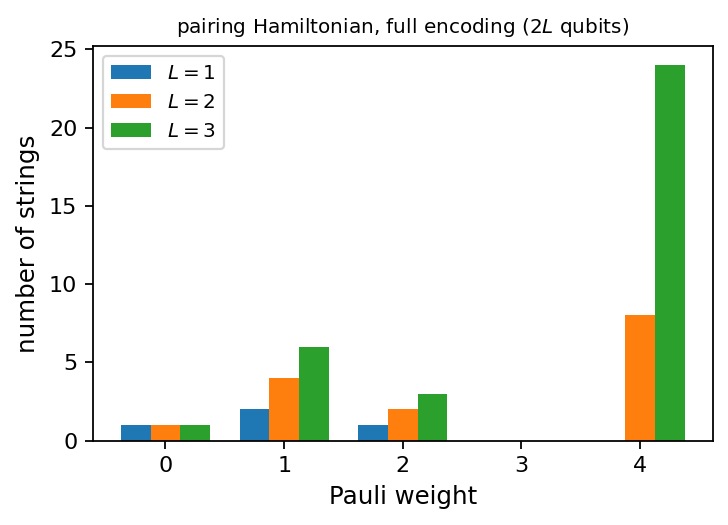

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/jw_basics.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== Lipkin model, N = Omega = 4, eps = 2, V = -1/3, W = -1/4 (Table 4.lipkinencodings)
              encoding  qubits  strings  max weight         E0
  one per spin-orbital       8       61           4   -4.21288
       one per doublet       4       16           2   -4.21288
       one-hot |J,J_z>       5       12           2   -4.21288
   binary, J = 2 block       3       16           3   -4.21288
level encoding, Pauli form:
-1.0000 IIIZ
-1.0000 IIZI
-1.0000 IZII
-1.0000 ZIII
-0.2917 IIXX
+0.0417 IIYY
-0.2917 IXIX
-0.2917 IXXI
+0.0417 IYIY
+0.0417 IYYI
-0.2917 XIIX
-0.2917 XIXI
-0.2917 XXII
+0.0417 YIIY
+0.0417 YIYI
+0.0417 YYII

=== Pairing model, L = 2, xi = 1, g = 1, one qubit per spin-orbital (Eq. 4.jwpairingfull)
+0.7500 IIII
-0.3750 IIIZ
-0.3750 IIZI
+0.1250 IZII
+0.1250 ZIII
-0.1250 IIZZ
-0.1250 ZZII
-0.0625 XXXX
+0.0625 XXYY
-0.0625 XYXY
-0.0625 XYYX
-0.0625 YXXY
-0.0625 YXYX
+0.0625 YYXX
-0.0625 YYYY

=== Pairing model, one qubit per level (Eq. 4.jwpairingtwolevels)
+0.5000 I

spin-major (all up, all down)       29           4              {2: 12, 4: 4}
  ground-state energy from the qubit Hamiltonian -2.10274848 (chapter 3: -2.10274848)

=== Heisenberg ring, 4 sites: already a Pauli sum
+0.2500 IIXX
+0.2500 IIYY
+0.2500 IIZZ
+0.2500 IXXI
+0.2500 IYYI
+0.2500 IZZI
+0.2500 XIIX
+0.2500 XXII
+0.2500 YIIY
+0.2500 YYII
+0.2500 ZIIZ
+0.2500 ZZII
fermionic form: the open bonds give the same Pauli strings; the closing bond (3,0) carries a parity string:
{'IZZI': 0.25, 'XZZX': 0.25, 'YZZY': 0.25}
  lowest eigenvalues with two fermions: [-1.61803 -1.61803 -0.     ] -- not the spin ring's -2:
  the parity string twists the boundary condition (Sec. 4.4); the spin form is the one to use

=== Symmetries as vanishing commutators of Pauli sums (Table 4.symmetries)
    Hubbard ring: [H, N] = 0; [H, S^z] = 0; [H, parity] = 0
     pairing L=4: [H, N] = 0; [H, parity] = 0; [H, seniority] = 0
   pairing + p-h: [H, N] = 0; [H, parity] = 0; [H, seniority] = 432 strings, norm boun

          Hubbard ring, spin-major   24.000   16.000            72.000
                   Heisenberg ring    3.000    2.000             3.000

=== Measurement settings: groups of qubit-wise commuting strings (Table 4.settings)
                       Hamiltonian  qubits  strings  settings
           Lipkin, one per doublet       4       16         3
        pairing L=4, one per level       4       17         3
      pairing L=4, one per orbital       8       61        17
          Hubbard ring, spin-major       8       29         5
                   Heisenberg ring       4       12         3
  Heisenberg groups: [['IIXX', 'IXXI', 'XIIX', 'XXII'], ['IIYY', 'IYYI', 'YIIY', 'YYII'], ['IIZZ', 'IZZI', 'ZIIZ', 'ZZII']]

=== Tapering a Z2 symmetry: the two-level pairing model on one qubit (Eq. 4.tapered)
  after CNOT_01: {'II': 0.5, 'XI': -0.25, 'XZ': 0.25, 'ZI': 0.25, 'ZZ': -0.75}
  one-qubit Hamiltonian: {'I': 0.5, 'X': -0.5, 'Z': 1.0}
  eigenvalues [-0.61803  1.61803] = seniority-zero spec

figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter4/encodings.pdf


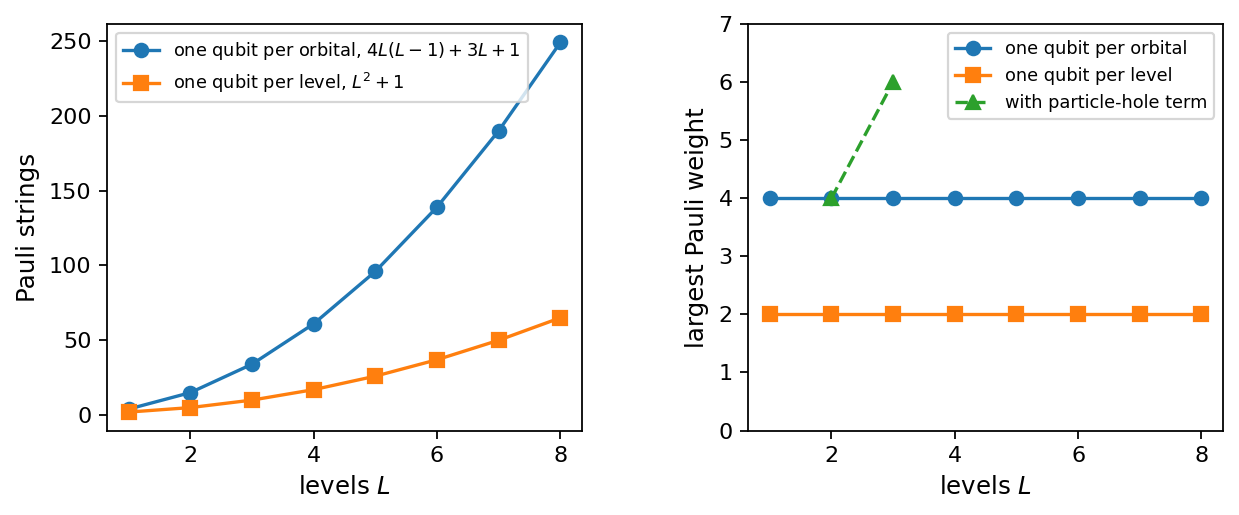

In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/mapped_models.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== Circuits for exp(-i theta P) (Fig. 4.gadget)
  ZZ: 3 gates, 2 CNOTs, depth 3
  XX: 7 gates, 2 CNOTs, depth 5
  YY: 11 gates, 2 CNOTs, depth 7
  XZZY: 13 gates, 6 CNOTs, depth 9
  XYXY: 19 gates, 6 CNOTs, depth 11
q0: |0>--[S^]-[H]-----------*--------*----------[H]-[S]--
q1: |0>-----------[S^]-[H]-(+)-[Rz]-(+)-[H]-[S]----------

=== One Trotter step as a circuit (Table 4.trottergates)
               Hamiltonian  strings  gates  CNOTs  depth
pairing L=2, one per level        5     20      4     14
  Heisenberg ring, 4 sites       12     84     24     55
pairing model, L = 2, one qubit per level, one first-order step:
q0: |0>--[Rz]-[H]------*--------*------[H]-[S^]-[H]-----------*--------*----------[H]-[S]-------
q1: |0>-----------[H]-(+)-[Rz]-(+)-[H]--------------[S^]-[H]-(+)-[Rz]-(+)-[H]-[S]---------[Rz]--

  splitting error of n steps for the pairing Hamiltonian, t = 1:
   n  first order  second order
   1    2.426e-01     5.587e-02
   2    1.056e-01     1.242e-02
   4    5.089e-02

  second order, dt = 0.25: 46 CNOTs per step, largest error 3.85e-03

=== Energy from shots, pairing L = 2, one pair (Table 4.shots)
  qubit-wise commuting groups of the 5 strings: [['XX', 'II'], ['YY'], ['ZI', 'IZ']]
 shots/group  one estimate  rms error (20 runs)  rms x sqrt(shots)
         100      -0.63000             6.52e-02              0.652
        1000      -0.61500             1.64e-02              0.520


       10000      -0.60780             5.54e-03              0.554


      100000      -0.61936             1.72e-03              0.543
  exact energy -0.61803399; 3 measurement settings; the error falls as 1/sqrt(shots)

=== Variances of the strings and the shots needed for 1e-3 (Table 4.variances)
  string        h      <P>    Var P
    IIII   5.0000   1.0000   0.0000
    IIIZ  -2.7500   0.9764   0.0467
    ZIII   0.2500  -0.7883   0.3786
    XXII  -0.2500   0.5014   0.7486
    YYII  -0.2500   0.5014   0.7486
    XIIX  -0.2500   0.2055   0.9578
  17 strings; optimal allocation S_a ~ |h_a| sigma_a: total shots 2.08e+07; naive bound (sum|h|)^2/eps^2 = 1.82e+08

=== The pair-excitation circuit exp(theta (S+_1 S-_0 - h.c.)) (Fig. 4.pairgadget)
  generator S+_1 S-_0 - h.c. = {'YX': 0.5j, 'XY': -0.5j}
q0: |0>--[S^]-[H]------*--------*------[H]-[S]-[H]-----------*--------*----------[H]--
q1: |0>-----------[H]-(+)-[Rz]-(+)-[H]-------------[S^]-[H]-(+)-[Rz]-(+)-[H]-[S]------
  E(theta) minimal at theta = 0.227: -0.617980; exact -0.618034; E(theta) = -0.500 cos

 1.00   0.0000         -2.000000         -2.000000  -2.309401
 1.50   0.8411         -2.166667         -2.166667  -2.645751
 2.00   1.0472         -2.500000         -2.500000  -3.055050
 2.50   1.1593         -2.900000         -2.900000  -3.511885

=== Trotterised UCC circuit for the pairing model, L = 4, two pairs (Table 4.uccd)
    g     E_ref  circuit UCCD   chapter 3          FCI  CNOTs


...

 1.00    1.0000    0.63698698  0.63698698   0.63554847     16


 1.50    0.5000   -0.33675149 -0.33675149  -0.34819051     16


 2.00    0.0000   -1.45347633 -1.45347633  -1.48965216     16
  the circuit is the n = 1 Trotter product of chapter 3 with re-optimised amplitudes;
  74 gates, 16 CNOTs, depth 38, four parameters


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter4/dynamics.pdf


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter4/circuits.pdf


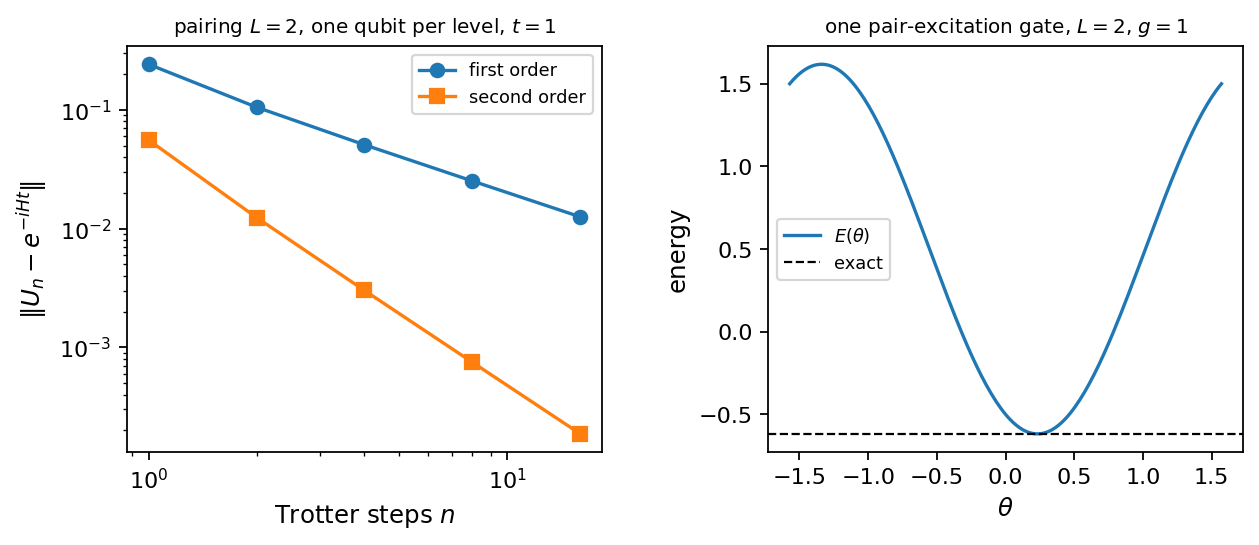

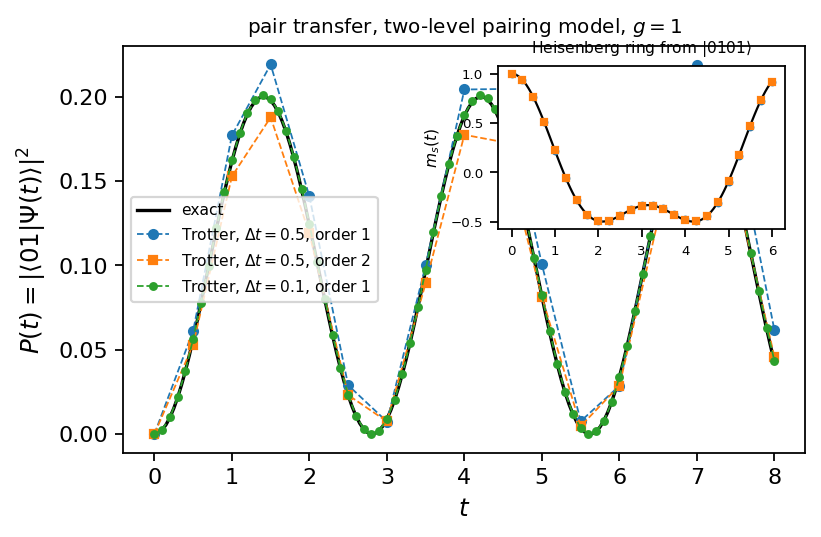

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter4/pauli_circuits.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter4').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
